# DINOv2 ViT-S/14 Transfer Learning Baseline

DINOv2 ViT-S/14 provides self-supervised Vision Transformer representations learned from the LVD-142M image collection. It is evaluated as the final new architecture baseline after ResNet50, EfficientNetV2-S, and ConvNeXt-Tiny.

The same cleaned train/validation/test split is reused without modification. Architecture selection uses validation results only; the test subset remains frozen and untouched.


## 1. Imports and Reproducibility

All random generators use the project seed. Deterministic PyTorch behavior is requested where available, with warnings permitted for operations without deterministic implementations. No packages are installed from within this notebook.


In [1]:
from pathlib import Path
import os
import random
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from PIL import Image, ImageOps
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
)
import torch
import torchvision
from torch import nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm

RANDOM_SEED = 42


def set_reproducible_seed(seed: int) -> None:
    """Configure deterministic random states for Python, NumPy, and PyTorch."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)


set_reproducible_seed(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CUDA_AVAILABLE = torch.cuda.is_available()
GPU_NAME = torch.cuda.get_device_name(0) if CUDA_AVAILABLE else "Not available"
GPU_MEMORY_GB = (
    torch.cuda.get_device_properties(0).total_memory / 1024**3
    if CUDA_AVAILABLE
    else 0.0
)

print(f"PyTorch version: {torch.__version__}")
print(f"torchvision version: {torchvision.__version__}")
print(f"CUDA available: {CUDA_AVAILABLE}")
print(f"CUDA runtime: {torch.version.cuda}")
print(f"Selected device: {DEVICE}")
print(f"GPU name: {GPU_NAME}")
print(
    f"Total GPU memory: {GPU_MEMORY_GB:.2f} GB"
    if CUDA_AVAILABLE
    else "Total GPU memory: Not available"
)


PyTorch version: 2.13.0+cu132
torchvision version: 0.28.0+cu132
CUDA available: True
CUDA runtime: 13.2
Selected device: cuda
GPU name: NVIDIA GeForce RTX 3060 Laptop GPU
Total GPU memory: 6.00 GB


## 2. Project Paths and Local Torch Cache

The project root is detected from the current working directory. The processed split must already exist. Model repository files and weights downloaded by `torch.hub` are retained in the project-local cache so repeated notebook executions do not download them again.


In [2]:
RAW_RELATIVE_PATH = Path("data/raw/skin-diseases-image-dataset/IMG_CLASSES")


def find_project_root(start: Path) -> Path:
    """Find the nearest parent containing the raw dataset and processed manifests."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (
            (candidate / RAW_RELATIVE_PATH).is_dir()
            and (candidate / "data" / "processed").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root containing the raw dataset and "
        "data/processed."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DATA_DIR = PROJECT_ROOT / RAW_RELATIVE_PATH
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
PREDICTIONS_DIR = REPORTS_DIR / "predictions"
MODELS_DIR = PROJECT_ROOT / "models"
TORCH_CACHE_DIR = MODELS_DIR / "torch_cache"

for directory in [
    REPORTS_DIR,
    FIGURES_DIR,
    PREDICTIONS_DIR,
    MODELS_DIR,
    TORCH_CACHE_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

torch.hub.set_dir(str(TORCH_CACHE_DIR))

MANIFEST_PATHS = {
    "train": PROCESSED_DIR / "train.csv",
    "validation": PROCESSED_DIR / "validation.csv",
    "test": PROCESSED_DIR / "test.csv",
}
missing_manifests = [path for path in MANIFEST_PATHS.values() if not path.is_file()]
if missing_manifests:
    missing_text = "\n".join(f"  - {path}" for path in missing_manifests)
    raise FileNotFoundError(
        "Processed manifests are missing. Execute "
        "notebooks/02_dataset_cleaning_and_split.ipynb first. Missing files:\n"
        f"{missing_text}"
    )

CHECKPOINT_PATH = MODELS_DIR / "dinov2_vits14_baseline_best.pth"

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw dataset: {RAW_DATA_DIR}")
print(f"Model checkpoint: {CHECKPOINT_PATH}")
print(f"Torch Hub cache: {torch.hub.get_dir()}")


Project root: C:\Projekt konferencyjny Turcja\skin-disease-classification
Raw dataset: C:\Projekt konferencyjny Turcja\skin-disease-classification\data\raw\skin-diseases-image-dataset\IMG_CLASSES
Model checkpoint: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\dinov2_vits14_baseline_best.pth
Torch Hub cache: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\torch_cache


## 3. Load and Validate Manifests

The train, validation, and test manifests are checked for required fields, valid class identifiers, retained group assignments, referenced files, and split separation. The test table is not converted into a dataset or loader, and no test inference is performed.


In [3]:
manifests = {
    split_name: pd.read_csv(path)
    for split_name, path in MANIFEST_PATHS.items()
}
REQUIRED_COLUMNS = {"relative_path", "class_name", "class_id", "group_id"}

for split_name, manifest in manifests.items():
    missing_columns = REQUIRED_COLUMNS - set(manifest.columns)
    if missing_columns:
        raise ValueError(
            f"{MANIFEST_PATHS[split_name].name} is missing columns: "
            f"{sorted(missing_columns)}"
        )
    if manifest[list(REQUIRED_COLUMNS)].isna().any().any():
        raise ValueError(
            f"Required values are missing in {MANIFEST_PATHS[split_name].name}."
        )
    if manifest["relative_path"].duplicated().any():
        raise ValueError(f"Duplicate paths exist within the {split_name} manifest.")
    if "split" in manifest.columns and not manifest["split"].eq(split_name).all():
        raise ValueError(
            f"The split column is inconsistent in "
            f"{MANIFEST_PATHS[split_name].name}."
        )
    numeric_class_ids = pd.to_numeric(manifest["class_id"], errors="coerce")
    if numeric_class_ids.isna().any() or not np.equal(
        numeric_class_ids, numeric_class_ids.astype(int)
    ).all():
        raise ValueError(f"Non-integer class IDs exist in the {split_name} manifest.")

all_paths = pd.concat(
    [
        manifest[["relative_path"]].assign(source_split=split_name)
        for split_name, manifest in manifests.items()
    ],
    ignore_index=True,
)
if all_paths["relative_path"].duplicated().any():
    duplicated_paths = all_paths.loc[
        all_paths["relative_path"].duplicated(keep=False), "relative_path"
    ]
    raise ValueError(
        f"{duplicated_paths.nunique():,} image path(s) occur in more than one split."
    )

all_groups = pd.concat(
    [
        manifest[["group_id"]].assign(source_split=split_name)
        for split_name, manifest in manifests.items()
    ],
    ignore_index=True,
)
group_split_counts = all_groups.groupby("group_id")["source_split"].nunique()
if (group_split_counts > 1).any():
    raise ValueError(
        f"{int((group_split_counts > 1).sum()):,} group ID(s) occur across splits."
    )

missing_images = [
    relative_path
    for relative_path in all_paths["relative_path"]
    if not (PROJECT_ROOT / relative_path).is_file()
]
if missing_images:
    raise FileNotFoundError(
        f"{len(missing_images):,} manifest image paths do not exist on disk."
    )

split_summary = pd.DataFrame(
    {
        "split": list(manifests),
        "images": [len(manifests[name]) for name in manifests],
    }
)
split_summary["percentage"] = (
    100 * split_summary["images"] / split_summary["images"].sum()
)
display(split_summary)

class_distribution = pd.concat(
    [
        manifest.groupby(["class_id", "class_name"])
        .size()
        .rename("images")
        .reset_index()
        .assign(split=split_name)
        for split_name, manifest in manifests.items()
    ],
    ignore_index=True,
)
display(class_distribution.sort_values(["class_id", "split"]))

print(f"Training images: {len(manifests['train']):,}")
print(f"Validation images: {len(manifests['validation']):,}")
print(f"Frozen test images (structural validation only): {len(manifests['test']):,}")
print(f"Unique paths across all splits: {all_paths['relative_path'].nunique():,}")
print(f"Unique group IDs across all splits: {all_groups['group_id'].nunique():,}")


,split,images,percentage
0,train,18491,70.009844
1,validation,3961,14.996971
2,test,3960,14.993185


,class_id,class_name,images,split
20,0,Eczema,230,test
0,0,Eczema,1068,train
10,0,Eczema,228,validation
21,1,Melanoma,470,test
1,1,Melanoma,2195,train
11,1,Melanoma,471,validation
22,2,Atopic Dermatitis,174,test
2,2,Atopic Dermatitis,804,train
12,2,Atopic Dermatitis,171,validation
23,3,Basal Cell Carcinoma (BCC),496,test


Training images: 18,491
Validation images: 3,961
Frozen test images (structural validation only): 3,960
Unique paths across all splits: 26,412
Unique group IDs across all splits: 26,293


## 4. Class Mapping

Class identifiers and names are taken directly from the manifests. Folder ordering is not used to infer labels. A one-to-one, contiguous mapping must be shared by all three splits.


In [4]:
mapping_frames = []
for split_name, manifest in manifests.items():
    split_mapping = manifest[["class_id", "class_name"]].drop_duplicates().copy()
    split_mapping["class_id"] = split_mapping["class_id"].astype(int)
    if (
        split_mapping["class_id"].duplicated().any()
        or split_mapping["class_name"].duplicated().any()
    ):
        raise ValueError(
            f"The class mapping is not one-to-one in the {split_name} manifest."
        )
    mapping_frames.append(split_mapping.assign(split=split_name))

mapping_check = pd.concat(mapping_frames, ignore_index=True)
class_mapping_table = (
    mapping_check[["class_id", "class_name"]]
    .drop_duplicates()
    .sort_values("class_id", ignore_index=True)
)
if mapping_check.groupby("split").size().nunique() != 1:
    raise ValueError("The manifests do not contain the same number of classes.")
if class_mapping_table["class_id"].tolist() != list(range(len(class_mapping_table))):
    raise ValueError("Class IDs are not contiguous from zero.")
for split_name, split_mapping in mapping_check.groupby("split"):
    observed = (
        split_mapping[["class_id", "class_name"]]
        .sort_values("class_id")
        .reset_index(drop=True)
    )
    if not observed.equals(class_mapping_table):
        raise ValueError(f"Class mapping differs in the {split_name} manifest.")

CLASS_ID_TO_NAME = dict(
    zip(class_mapping_table["class_id"], class_mapping_table["class_name"])
)
NUM_CLASSES = len(CLASS_ID_TO_NAME)
display(class_mapping_table)
print(f"Number of classes: {NUM_CLASSES}")


,class_id,class_name
0,0,Eczema
1,1,Melanoma
2,2,Atopic Dermatitis
3,3,Basal Cell Carcinoma (BCC)
4,4,Melanocytic Nevi (NV)
5,5,Benign Keratosis-like Lesions (BKL)
6,6,Psoriasis / Lichen Planus / Related Diseases
7,7,Seborrheic Keratoses / Other Benign Tumors
8,8,Tinea / Ringworm / Candidiasis / Other Fungal ...
9,9,Warts / Molluscum / Other Viral Infections


Number of classes: 10


## 5. DINOv2 Input Resolution and Transformations

DINOv2 ViT-S/14 uses 14 x 14 image patches. `IMAGE_SIZE = 224` produces a 16 x 16 patch grid because 224 / 14 = 16, while remaining practical for a GPU with approximately 6 GB of memory.

This resolution differs from the resolution used by the EfficientNetV2-S pretrained pipeline. The experiments therefore compare practical pretrained pipelines rather than a strict architecture-only ablation. Training augmentation remains moderate, and validation preprocessing is deterministic. Raw images are never modified or resized on disk.


In [5]:
IMAGE_SIZE = 224
PATCH_SIZE = 14
VALIDATION_RESIZE_SIZE = 256
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

if IMAGE_SIZE % PATCH_SIZE != 0:
    raise ValueError(
        f"IMAGE_SIZE={IMAGE_SIZE} must be divisible by patch size {PATCH_SIZE}."
    )

train_transform = transforms.Compose(
    [
        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(0.80, 1.00),
            ratio=(0.90, 1.10),
            interpolation=InterpolationMode.BICUBIC,
            antialias=True,
        ),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(
            degrees=10,
            interpolation=InterpolationMode.BICUBIC,
        ),
        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.10,
            hue=0.02,
        ),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)

validation_transform = transforms.Compose(
    [
        transforms.Resize(
            VALIDATION_RESIZE_SIZE,
            interpolation=InterpolationMode.BICUBIC,
            antialias=True,
        ),
        transforms.CenterCrop(IMAGE_SIZE),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)

print(f"Image size: {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Patch grid: {IMAGE_SIZE // PATCH_SIZE} x {IMAGE_SIZE // PATCH_SIZE}")
print(f"Validation resize size: {VALIDATION_RESIZE_SIZE}")
print(f"Normalization mean: {IMAGENET_MEAN}")
print(f"Normalization standard deviation: {IMAGENET_STD}")


Image size: 224 x 224
Patch grid: 16 x 16
Validation resize size: 256
Normalization mean: [0.485, 0.456, 0.406]
Normalization standard deviation: [0.229, 0.224, 0.225]


## 6. Dataset and DataLoaders

Each image is resolved from the manifest's `relative_path`, corrected for EXIF orientation, converted to RGB, and transformed in memory. Labels come exclusively from the manifest.

A batch size of 16 is the conservative starting configuration for an RTX 3060 with 6 GB of memory. If CUDA reports an out-of-memory error, stop the run, set `BATCH_SIZE = 8`, restart the kernel, and execute the notebook again from the beginning. The batch size is not changed silently.


In [6]:
class SkinDiseaseDataset(Dataset):
    """Load images and labels directly from a processed manifest."""

    def __init__(self, manifest: pd.DataFrame, project_root: Path, transform=None):
        self.manifest = manifest.reset_index(drop=True).copy()
        self.project_root = project_root
        self.transform = transform

    def __len__(self) -> int:
        return len(self.manifest)

    def __getitem__(self, index: int):
        row = self.manifest.iloc[index]
        image_path = self.project_root / row["relative_path"]
        with Image.open(image_path) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            if self.transform is not None:
                image = self.transform(image)
        return image, int(row["class_id"]), row["relative_path"]


train_dataset = SkinDiseaseDataset(
    manifests["train"], PROJECT_ROOT, transform=train_transform
)
validation_dataset = SkinDiseaseDataset(
    manifests["validation"], PROJECT_ROOT, transform=validation_transform
)

BATCH_SIZE = 16
NUM_WORKERS = 0  # Reliable for Windows and interactive Jupyter execution.
PIN_MEMORY = CUDA_AVAILABLE

train_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    generator=train_generator,
    persistent_workers=NUM_WORKERS > 0,
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=NUM_WORKERS > 0,
)

print(f"Training batches: {len(train_loader):,}")
print(f"Validation batches: {len(validation_loader):,}")
print(f"Batch size: {BATCH_SIZE}")
print(f"DataLoader workers: {NUM_WORKERS}")
print(f"Pinned memory: {PIN_MEMORY}")


Training batches: 1,156
Validation batches: 248
Batch size: 16
DataLoader workers: 0
Pinned memory: True


## 7. Data Sanity Check

A small augmented training batch is converted back to display space. This verifies that preprocessing preserves usable image content and does not constitute medical interpretation.


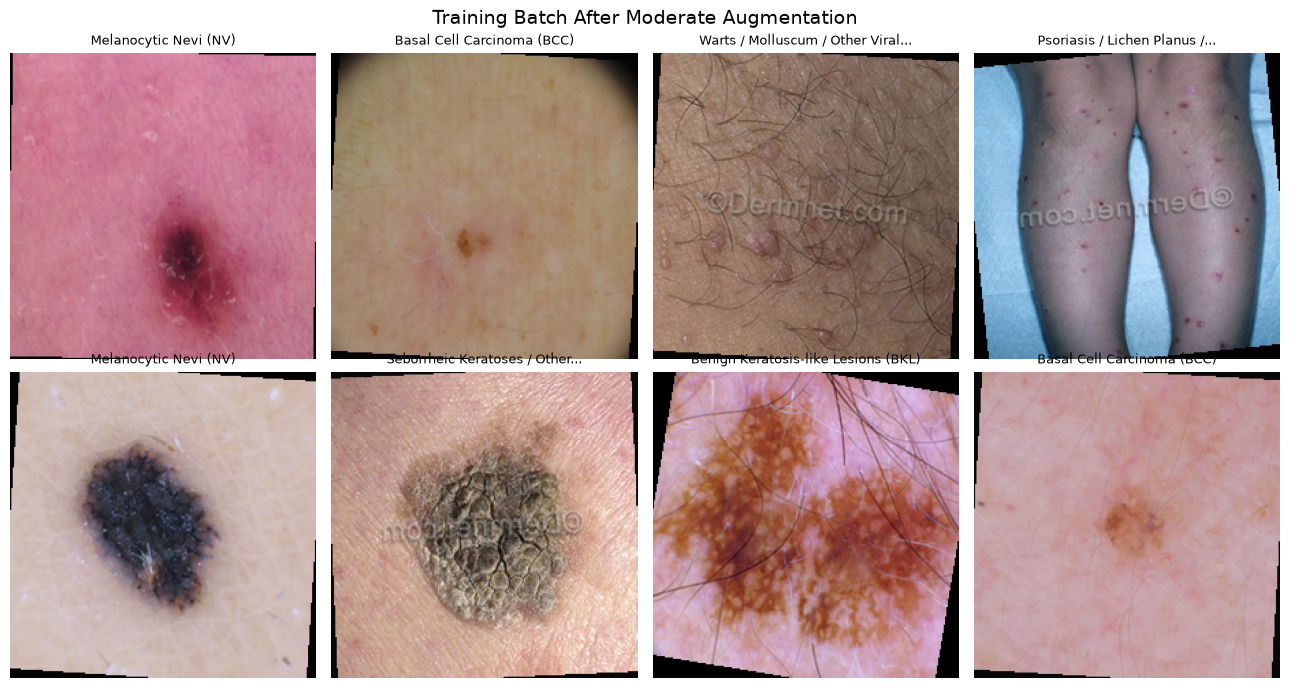

In [7]:
sample_images, sample_labels, _ = next(iter(train_loader))
train_generator.manual_seed(RANDOM_SEED)

mean_tensor = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std_tensor = torch.tensor(IMAGENET_STD).view(3, 1, 1)
display_count = min(8, len(sample_images))

fig, axes = plt.subplots(2, 4, figsize=(13, 7), squeeze=False)
for axis, image_tensor, label in zip(
    axes.flat, sample_images[:display_count], sample_labels[:display_count]
):
    image_for_display = (image_tensor.cpu() * std_tensor + mean_tensor).clamp(0, 1)
    axis.imshow(image_for_display.permute(1, 2, 0).numpy())
    axis.set_title(
        textwrap.shorten(
            CLASS_ID_TO_NAME[int(label)], width=35, placeholder="..."
        ),
        fontsize=9,
    )
    axis.axis("off")
for axis in axes.flat[display_count:]:
    axis.axis("off")
fig.suptitle("Training Batch After Moderate Augmentation", fontsize=14)
fig.tight_layout()
plt.show()


## 8. Load DINOv2 ViT-S/14 and Define the Classifier

The official `facebookresearch/dinov2` PyTorch Hub entry loads the ViT-S/14 backbone with pretrained LVD-142M weights. The project-local Hub cache is reused on subsequent executions. Download failure raises an explicit error; no substitute architecture or random initialization is used.

The backbone's global representation is passed through dropout and a new linear classifier. The embedding dimension and transformer blocks are discovered from the loaded model rather than assumed from a different Vision Transformer implementation.


In [8]:
DINOV2_REPOSITORY = "facebookresearch/dinov2"
DINOV2_MODEL_NAME = "dinov2_vits14"
PRETRAINED_SOURCE = "Official Meta DINOv2 PyTorch Hub repository"
PRETRAINED_WEIGHTS = "Official DINOv2 ViT-S/14 LVD-142M weights"

print(f"Resolved Torch Hub cache directory: {torch.hub.get_dir()}")
try:
    dinov2_backbone = torch.hub.load(
        DINOV2_REPOSITORY,
        DINOV2_MODEL_NAME,
        trust_repo=True,
    )
except Exception as error:
    raise RuntimeError(
        "DINOv2 ViT-S/14 could not be loaded from the official "
        "facebookresearch/dinov2 PyTorch Hub repository. Confirm internet "
        "access for the first execution or verify that the repository and "
        "weights are already present in the printed project-local Torch Hub "
        "cache. No alternative model has been substituted."
    ) from error

embedding_dimension = getattr(dinov2_backbone, "embed_dim", None)
if embedding_dimension is None:
    embedding_dimension = getattr(dinov2_backbone, "num_features", None)
if embedding_dimension is None:
    raise AttributeError(
        "The loaded DINOv2 backbone does not expose embed_dim or num_features."
    )
embedding_dimension = int(embedding_dimension)

transformer_blocks = getattr(dinov2_backbone, "blocks", None)
if not isinstance(transformer_blocks, (nn.ModuleList, nn.Sequential)):
    raise AttributeError(
        "The loaded DINOv2 backbone does not expose transformer blocks through "
        "a supported 'blocks' container."
    )
if len(transformer_blocks) < 2:
    raise ValueError("At least two transformer blocks are required for Stage 2.")


class DINOv2Classifier(nn.Module):
    """DINOv2 global representation with a task-specific classification head."""

    def __init__(
        self,
        backbone: nn.Module,
        embedding_dim: int,
        num_classes: int,
        dropout_probability: float,
    ):
        super().__init__()
        self.backbone = backbone
        self.dropout = nn.Dropout(p=dropout_probability)
        self.classifier = nn.Linear(embedding_dim, num_classes)

    def forward(self, images):
        features = self.backbone(images)
        if isinstance(features, dict):
            if "x_norm_clstoken" not in features:
                raise KeyError(
                    "The DINOv2 feature dictionary does not contain "
                    "'x_norm_clstoken'."
                )
            features = features["x_norm_clstoken"]
        elif isinstance(features, (tuple, list)):
            features = features[0]
        if features.ndim != 2 or features.shape[1] != embedding_dimension:
            raise ValueError(
                "Unexpected DINOv2 global representation shape: "
                f"{tuple(features.shape)}"
            )
        return self.classifier(self.dropout(features))


CLASSIFIER_DROPOUT = 0.20
model = DINOv2Classifier(
    backbone=dinov2_backbone,
    embedding_dim=embedding_dimension,
    num_classes=NUM_CLASSES,
    dropout_probability=CLASSIFIER_DROPOUT,
).to(DEVICE)

total_parameters = sum(parameter.numel() for parameter in model.parameters())
initial_trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)

print("Architecture: DINOv2 ViT-S/14")
print(f"Hub model: {DINOV2_MODEL_NAME}")
print(f"Embedding dimension: {embedding_dimension}")
print(f"Transformer blocks: {len(transformer_blocks)}")
print(f"Total parameters: {total_parameters:,}")
print(f"Initially trainable parameters: {initial_trainable_parameters:,}")
print(f"Output classes: {NUM_CLASSES}")


Resolved Torch Hub cache directory: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\torch_cache
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to C:\Projekt konferencyjny Turcja\skin-disease-classification\models\torch_cache\main.zip


C:\Projekt konferencyjny Turcja\skin-disease-classification\models\torch_cache\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Projekt konferencyjny Turcja\skin-disease-classification\models\torch_cache\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Projekt konferencyjny Turcja\skin-disease-classification\models\torch_cache\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to C:\Projekt konferencyjny Turcja\skin-disease-classification\models\torch_cache\checkpoints\dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:34<00:00, 2.53MB/s]


Architecture: DINOv2 ViT-S/14
Hub model: dinov2_vits14
Embedding dimension: 384
Transformer blocks: 12
Total parameters: 22,060,426
Initially trainable parameters: 22,060,426
Output classes: 10


## 9. Staged Training Configuration

Stage 1 fits only the linear classification head. Stage 2 unfreezes the final two transformer blocks and the final backbone normalization layer, using a lower learning rate for pretrained parameters than for the classifier.

Stage 3 is implemented but disabled by default. It is not required for baseline completion because full-network tuning increases memory use and overfitting risk on the available hardware. If it is enabled manually, AMP remains active and the batch size should be reduced to 8 if the full network exceeds available VRAM. No class weights, focal loss, weighted sampling, MixUp, CutMix, or broad hyperparameter search is used.


In [9]:
WARMUP_EPOCHS = 3
PARTIAL_FINE_TUNE_MAX_EPOCHS = 15
FULL_FINE_TUNE_MAX_EPOCHS = 5
PARTIAL_UNFROZEN_BLOCKS = 2
ENABLE_FULL_FINE_TUNING = False

WARMUP_CLASSIFIER_LEARNING_RATE = 1e-3
PARTIAL_CLASSIFIER_LEARNING_RATE = 1e-4
PARTIAL_BACKBONE_LEARNING_RATE = 1e-5
FULL_CLASSIFIER_LEARNING_RATE = 1e-4
FULL_BACKBONE_LEARNING_RATE = 2e-6
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 5
CHECKPOINT_CRITERION = "validation_macro_f1"

TRAINING_CONFIGURATION = {
    "random_seed": RANDOM_SEED,
    "architecture": "DINOv2 ViT-S/14",
    "pretrained_source": PRETRAINED_SOURCE,
    "pretrained_weights": PRETRAINED_WEIGHTS,
    "hub_repository": DINOV2_REPOSITORY,
    "hub_model": DINOV2_MODEL_NAME,
    "embedding_dimension": embedding_dimension,
    "image_size": IMAGE_SIZE,
    "patch_size": PATCH_SIZE,
    "batch_size": BATCH_SIZE,
    "classifier_dropout": CLASSIFIER_DROPOUT,
    "optimizer": "AdamW",
    "loss": "CrossEntropyLoss (unweighted)",
    "warmup_classifier_learning_rate": WARMUP_CLASSIFIER_LEARNING_RATE,
    "partial_classifier_learning_rate": PARTIAL_CLASSIFIER_LEARNING_RATE,
    "partial_backbone_learning_rate": PARTIAL_BACKBONE_LEARNING_RATE,
    "full_classifier_learning_rate": FULL_CLASSIFIER_LEARNING_RATE,
    "full_backbone_learning_rate": FULL_BACKBONE_LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "warmup_epochs": WARMUP_EPOCHS,
    "partial_fine_tune_max_epochs": PARTIAL_FINE_TUNE_MAX_EPOCHS,
    "full_fine_tune_enabled": ENABLE_FULL_FINE_TUNING,
    "full_fine_tune_max_epochs": FULL_FINE_TUNE_MAX_EPOCHS,
    "partial_unfrozen_blocks": PARTIAL_UNFROZEN_BLOCKS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "checkpoint_criterion": CHECKPOINT_CRITERION,
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "cuda_version": torch.version.cuda,
    "gpu_name": GPU_NAME,
}

display(
    pd.DataFrame(
        {
            "Configuration Item": list(TRAINING_CONFIGURATION),
            "Value": list(TRAINING_CONFIGURATION.values()),
        }
    )
)


,Configuration Item,Value
0,random_seed,42
1,architecture,DINOv2 ViT-S/14
2,pretrained_source,Official Meta DINOv2 PyTorch Hub repository
3,pretrained_weights,Official DINOv2 ViT-S/14 LVD-142M weights
4,hub_repository,facebookresearch/dinov2
5,hub_model,dinov2_vits14
6,embedding_dimension,384
7,image_size,224
8,patch_size,14
9,batch_size,16


## 10. Training, Validation, and Checkpoint Functions

Loss is accumulated with sample weighting. Metric inputs are moved to CPU before scikit-learn calculations. CUDA uses the current `torch.amp` interface, while the same functions remain valid on CPU. CUDA memory errors are reported explicitly and never trigger a silent device fallback.


In [10]:
criterion = nn.CrossEntropyLoss()
AMP_ENABLED = DEVICE.type == "cuda"
HISTORY_PATH = REPORTS_DIR / "06_dinov2_training_history.csv"


def set_training_mode(
    model: nn.Module,
    backbone_mode: str,
    trainable_block_count: int = 0,
) -> None:
    """Set train/eval modes consistently with the active unfreezing stage."""
    model.train()
    if backbone_mode == "frozen":
        model.backbone.eval()
    elif backbone_mode == "partial":
        model.backbone.eval()
        for block in model.backbone.blocks[-trainable_block_count:]:
            block.train()
        final_norm = getattr(model.backbone, "norm", None)
        if final_norm is not None:
            final_norm.train()
    elif backbone_mode == "full":
        model.backbone.train()
    else:
        raise ValueError(f"Unknown backbone training mode: {backbone_mode}")
    model.classifier.train()


def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    device,
    backbone_mode: str,
    trainable_block_count: int = 0,
):
    """Train for one epoch and return sample-weighted loss and accuracy."""
    set_training_mode(model, backbone_mode, trainable_block_count)
    running_loss = 0.0
    correct_predictions = 0
    sample_count = 0

    progress = tqdm(loader, desc="Training", unit="batch", leave=False)
    for images, labels, _ in progress:
        try:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=AMP_ENABLED,
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        except torch.OutOfMemoryError as error:
            raise RuntimeError(
                "CUDA ran out of memory. Stop this run, set BATCH_SIZE to 8, "
                "restart the kernel, and rerun the notebook from the beginning. "
                "The notebook will not fall back to CPU automatically."
            ) from error

        current_batch_size = labels.size(0)
        running_loss += loss.detach().item() * current_batch_size
        correct_predictions += (
            logits.detach().argmax(dim=1) == labels
        ).sum().item()
        sample_count += current_batch_size
        progress.set_postfix(
            loss=f"{running_loss / sample_count:.4f}",
            accuracy=f"{correct_predictions / sample_count:.3f}",
        )

    return {
        "loss": running_loss / sample_count,
        "accuracy": correct_predictions / sample_count,
    }


def calculate_classification_metrics(targets, predictions) -> dict:
    """Calculate stage-selection metrics from CPU arrays."""
    return {
        "accuracy": accuracy_score(targets, predictions),
        "balanced_accuracy": balanced_accuracy_score(targets, predictions),
        "macro_f1": f1_score(
            targets, predictions, average="macro", zero_division=0
        ),
    }


@torch.inference_mode()
def evaluate_model(model, loader, criterion, device, description="Validation"):
    """Return validation metrics and CPU prediction information."""
    model.eval()
    running_loss = 0.0
    sample_count = 0
    targets = []
    predictions = []
    confidences = []
    probability_batches = []
    relative_paths = []

    progress = tqdm(loader, desc=description, unit="batch", leave=False)
    for images, labels, paths in progress:
        try:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.amp.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=AMP_ENABLED,
            ):
                logits = model(images)
                loss = criterion(logits, labels)
        except torch.OutOfMemoryError as error:
            raise RuntimeError(
                "CUDA ran out of memory during validation. Stop this run, set "
                "BATCH_SIZE to 8, restart the kernel, and rerun the notebook."
            ) from error

        probabilities = torch.softmax(logits.float(), dim=1)
        confidence, predicted = probabilities.max(dim=1)
        current_batch_size = labels.size(0)
        running_loss += loss.item() * current_batch_size
        sample_count += current_batch_size
        targets.extend(labels.cpu().numpy().tolist())
        predictions.extend(predicted.cpu().numpy().tolist())
        confidences.extend(confidence.cpu().numpy().tolist())
        probability_batches.append(probabilities.cpu().numpy())
        relative_paths.extend(paths)

    targets = np.asarray(targets, dtype=np.int64)
    predictions = np.asarray(predictions, dtype=np.int64)
    confidences = np.asarray(confidences, dtype=np.float32)
    probabilities = np.concatenate(probability_batches, axis=0)
    metric_values = calculate_classification_metrics(targets, predictions)

    return {
        "loss": running_loss / sample_count,
        **metric_values,
        "targets": targets,
        "predictions": predictions,
        "confidences": confidences,
        "probabilities": probabilities,
        "relative_paths": relative_paths,
    }


def save_best_checkpoint(
    path: Path,
    model,
    epoch: int,
    stage: str,
    validation_metrics: dict,
) -> None:
    """Save a macro-F1-selected model with reproducibility metadata."""
    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "architecture": "DINOv2 ViT-S/14",
            "class_mapping": CLASS_ID_TO_NAME,
            "embedding_dimension": embedding_dimension,
            "best_validation_macro_f1": validation_metrics["macro_f1"],
            "validation_accuracy": validation_metrics["accuracy"],
            "validation_balanced_accuracy": validation_metrics[
                "balanced_accuracy"
            ],
            "epoch": epoch,
            "stage": stage,
            "image_size": IMAGE_SIZE,
            "training_configuration": TRAINING_CONFIGURATION,
        },
        path,
    )


def load_model_checkpoint(path: Path, model, device):
    """Restore parameters from a saved DINOv2 classifier checkpoint."""
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)
    model.eval()
    return checkpoint


def record_epoch(
    history,
    epoch: int,
    stage: str,
    training_metrics: dict,
    validation_metrics: dict,
    backbone_learning_rate: float,
    classifier_learning_rate: float,
) -> None:
    """Append and persist one epoch using the shared history schema."""
    history.append(
        {
            "epoch": epoch,
            "stage": stage,
            "train_loss": training_metrics["loss"],
            "train_accuracy": training_metrics["accuracy"],
            "val_loss": validation_metrics["loss"],
            "val_accuracy": validation_metrics["accuracy"],
            "val_balanced_accuracy": validation_metrics["balanced_accuracy"],
            "val_macro_f1": validation_metrics["macro_f1"],
            "learning_rate": classifier_learning_rate,
            "backbone_learning_rate": backbone_learning_rate,
            "classifier_learning_rate": classifier_learning_rate,
        }
    )
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False, encoding="utf-8")


def update_best_model(
    validation_metrics: dict,
    epoch: int,
    stage: str,
    current_best: float,
):
    """Save an improved checkpoint and return the updated selection state."""
    if validation_metrics["macro_f1"] > current_best:
        save_best_checkpoint(
            CHECKPOINT_PATH, model, epoch, stage, validation_metrics
        )
        return validation_metrics["macro_f1"], epoch, stage, True
    return current_best, None, None, False


## 11. Staged DINOv2 Training

### Stage 1 - Linear Probe / Classifier Warm-Up

The complete DINOv2 backbone is frozen and kept in evaluation mode. Only the task-specific classifier is trained for three epochs.

### Stage 2 - Partial Backbone Fine-Tuning

The classifier, final two transformer blocks, and final backbone normalization layer are trainable. Earlier blocks remain frozen and in evaluation mode. Discriminative learning rates protect the pretrained representation while adapting its highest-level features.

### Stage 3 - Optional Full Fine-Tuning

Full fine-tuning is skipped when `ENABLE_FULL_FINE_TUNING = False`. If manually enabled in a later rerun, all backbone parameters are unfrozen with a very small learning rate. The baseline is complete and comparable after Stage 2.


In [11]:
history = []
best_validation_macro_f1 = -np.inf
best_epoch = None
best_stage = None
global_epoch = 0


def freeze_all_parameters(module: nn.Module) -> None:
    for parameter in module.parameters():
        parameter.requires_grad = False


def print_epoch_metrics(training_metrics, validation_metrics, note="") -> None:
    message = (
        f"train loss={training_metrics['loss']:.4f}, "
        f"train accuracy={training_metrics['accuracy']:.4f}, "
        f"val loss={validation_metrics['loss']:.4f}, "
        f"val accuracy={validation_metrics['accuracy']:.4f}, "
        f"val balanced accuracy={validation_metrics['balanced_accuracy']:.4f}, "
        f"val macro F1={validation_metrics['macro_f1']:.4f}"
    )
    print(f"{message}; {note}" if note else message)


# Stage 1: linear classifier warm-up.
freeze_all_parameters(model)
for parameter in model.classifier.parameters():
    parameter.requires_grad = True

warmup_trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)
print(f"Stage 1 trainable parameters: {warmup_trainable_parameters:,}")

warmup_optimizer = AdamW(
    model.classifier.parameters(),
    lr=WARMUP_CLASSIFIER_LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)
warmup_scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

for stage_epoch in range(1, WARMUP_EPOCHS + 1):
    global_epoch += 1
    print(
        f"Stage 1/3 - linear probe epoch {stage_epoch}/{WARMUP_EPOCHS}"
    )
    training_metrics = train_one_epoch(
        model,
        train_loader,
        criterion,
        warmup_optimizer,
        warmup_scaler,
        DEVICE,
        backbone_mode="frozen",
    )
    validation_metrics = evaluate_model(
        model, validation_loader, criterion, DEVICE
    )
    classifier_lr = warmup_optimizer.param_groups[0]["lr"]
    record_epoch(
        history,
        global_epoch,
        "linear_probe",
        training_metrics,
        validation_metrics,
        backbone_learning_rate=0.0,
        classifier_learning_rate=classifier_lr,
    )
    (
        updated_best,
        updated_epoch,
        updated_stage,
        checkpoint_updated,
    ) = update_best_model(
        validation_metrics,
        global_epoch,
        "linear_probe",
        best_validation_macro_f1,
    )
    if checkpoint_updated:
        best_validation_macro_f1 = updated_best
        best_epoch = updated_epoch
        best_stage = updated_stage
    print_epoch_metrics(
        training_metrics,
        validation_metrics,
        "checkpoint updated" if checkpoint_updated else "checkpoint unchanged",
    )

# Stage 2: partial DINOv2 fine-tuning.
freeze_all_parameters(model)
for parameter in model.classifier.parameters():
    parameter.requires_grad = True
for block in model.backbone.blocks[-PARTIAL_UNFROZEN_BLOCKS:]:
    for parameter in block.parameters():
        parameter.requires_grad = True
final_backbone_norm = getattr(model.backbone, "norm", None)
if final_backbone_norm is not None:
    for parameter in final_backbone_norm.parameters():
        parameter.requires_grad = True

partial_backbone_parameters = [
    parameter
    for parameter in model.backbone.parameters()
    if parameter.requires_grad
]
partial_trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)
print(f"Stage 2 trainable parameters: {partial_trainable_parameters:,}")
print(f"Unfrozen final transformer blocks: {PARTIAL_UNFROZEN_BLOCKS}")
print(f"Final backbone normalization trainable: {final_backbone_norm is not None}")

partial_optimizer = AdamW(
    [
        {
            "params": partial_backbone_parameters,
            "lr": PARTIAL_BACKBONE_LEARNING_RATE,
            "name": "backbone",
        },
        {
            "params": model.classifier.parameters(),
            "lr": PARTIAL_CLASSIFIER_LEARNING_RATE,
            "name": "classifier",
        },
    ],
    weight_decay=WEIGHT_DECAY,
)
partial_scheduler = ReduceLROnPlateau(
    partial_optimizer,
    mode="max",
    factor=0.3,
    patience=2,
    min_lr=1e-7,
)
partial_scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
epochs_without_improvement = 0

for stage_epoch in range(1, PARTIAL_FINE_TUNE_MAX_EPOCHS + 1):
    global_epoch += 1
    print(
        f"Stage 2/3 - partial fine-tuning epoch "
        f"{stage_epoch}/{PARTIAL_FINE_TUNE_MAX_EPOCHS}"
    )
    training_metrics = train_one_epoch(
        model,
        train_loader,
        criterion,
        partial_optimizer,
        partial_scaler,
        DEVICE,
        backbone_mode="partial",
        trainable_block_count=PARTIAL_UNFROZEN_BLOCKS,
    )
    validation_metrics = evaluate_model(
        model, validation_loader, criterion, DEVICE
    )
    backbone_lr = partial_optimizer.param_groups[0]["lr"]
    classifier_lr = partial_optimizer.param_groups[1]["lr"]
    record_epoch(
        history,
        global_epoch,
        "partial_fine_tuning",
        training_metrics,
        validation_metrics,
        backbone_learning_rate=backbone_lr,
        classifier_learning_rate=classifier_lr,
    )
    partial_scheduler.step(validation_metrics["macro_f1"])
    (
        updated_best,
        updated_epoch,
        updated_stage,
        checkpoint_updated,
    ) = update_best_model(
        validation_metrics,
        global_epoch,
        "partial_fine_tuning",
        best_validation_macro_f1,
    )
    if checkpoint_updated:
        best_validation_macro_f1 = updated_best
        best_epoch = updated_epoch
        best_stage = updated_stage
        epochs_without_improvement = 0
        improvement_note = "checkpoint updated"
    else:
        epochs_without_improvement += 1
        improvement_note = (
            f"no macro-F1 improvement for "
            f"{epochs_without_improvement} epoch(s)"
        )
    print_epoch_metrics(training_metrics, validation_metrics, improvement_note)

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(
            "Early stopping activated after "
            f"{EARLY_STOPPING_PATIENCE} partial fine-tuning epochs "
            "without improvement."
        )
        break

# Stage 3: optional full fine-tuning, disabled by default.
if ENABLE_FULL_FINE_TUNING:
    for parameter in model.parameters():
        parameter.requires_grad = True
    full_optimizer = AdamW(
        [
            {
                "params": model.backbone.parameters(),
                "lr": FULL_BACKBONE_LEARNING_RATE,
                "name": "backbone",
            },
            {
                "params": model.classifier.parameters(),
                "lr": FULL_CLASSIFIER_LEARNING_RATE,
                "name": "classifier",
            },
        ],
        weight_decay=WEIGHT_DECAY,
    )
    full_scheduler = ReduceLROnPlateau(
        full_optimizer,
        mode="max",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
    )
    full_scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
    full_epochs_without_improvement = 0

    for stage_epoch in range(1, FULL_FINE_TUNE_MAX_EPOCHS + 1):
        global_epoch += 1
        print(
            f"Stage 3/3 - optional full fine-tuning epoch "
            f"{stage_epoch}/{FULL_FINE_TUNE_MAX_EPOCHS}"
        )
        training_metrics = train_one_epoch(
            model,
            train_loader,
            criterion,
            full_optimizer,
            full_scaler,
            DEVICE,
            backbone_mode="full",
        )
        validation_metrics = evaluate_model(
            model, validation_loader, criterion, DEVICE
        )
        backbone_lr = full_optimizer.param_groups[0]["lr"]
        classifier_lr = full_optimizer.param_groups[1]["lr"]
        record_epoch(
            history,
            global_epoch,
            "full_fine_tuning",
            training_metrics,
            validation_metrics,
            backbone_learning_rate=backbone_lr,
            classifier_learning_rate=classifier_lr,
        )
        full_scheduler.step(validation_metrics["macro_f1"])
        (
            updated_best,
            updated_epoch,
            updated_stage,
            checkpoint_updated,
        ) = update_best_model(
            validation_metrics,
            global_epoch,
            "full_fine_tuning",
            best_validation_macro_f1,
        )
        if checkpoint_updated:
            best_validation_macro_f1 = updated_best
            best_epoch = updated_epoch
            best_stage = updated_stage
            full_epochs_without_improvement = 0
            improvement_note = "checkpoint updated"
        else:
            full_epochs_without_improvement += 1
            improvement_note = (
                f"no macro-F1 improvement for "
                f"{full_epochs_without_improvement} epoch(s)"
            )
        print_epoch_metrics(training_metrics, validation_metrics, improvement_note)
        if full_epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print("Optional full fine-tuning stopped early.")
            break
else:
    print("Stage 3 skipped: ENABLE_FULL_FINE_TUNING = False")

training_history = pd.DataFrame(history)
training_history.to_csv(HISTORY_PATH, index=False, encoding="utf-8")
display(training_history)
print(f"Best validation macro F1: {best_validation_macro_f1:.4f}")
print(f"Best epoch: {best_epoch} ({best_stage})")
print(f"Checkpoint saved to: {CHECKPOINT_PATH}")


Stage 1 trainable parameters: 3,850
Stage 1/3 - linear probe epoch 1/3


Training:   0%|          | 0/1156 [00:00<?, ?batch/s]

Validation:   0%|          | 0/248 [00:00<?, ?batch/s]

train loss=1.0393, train accuracy=0.6247, val loss=0.7909, val accuracy=0.7023, val balanced accuracy=0.5954, val macro F1=0.5969; checkpoint updated
Stage 1/3 - linear probe epoch 2/3


Training:   0%|          | 0/1156 [00:00<?, ?batch/s]

...

Training:   0%|          | 0/1156 [00:00<?, ?batch/s]

Validation:   0%|          | 0/248 [00:00<?, ?batch/s]

train loss=0.0457, train accuracy=0.9852, val loss=0.4932, val accuracy=0.8725, val balanced accuracy=0.8211, val macro F1=0.8204; checkpoint updated
Stage 3 skipped: ENABLE_FULL_FINE_TUNING = False


,epoch,stage,train_loss,train_accuracy,val_loss,val_accuracy,val_balanced_accuracy,val_macro_f1,learning_rate,backbone_learning_rate,classifier_learning_rate
0,1,linear_probe,1.039301,0.624682,0.790882,0.702348,0.595382,0.596919,0.00100,0.000000,0.00100
1,2,linear_probe,0.859851,0.681845,0.761114,0.715981,0.626523,0.624365,0.00100,0.000000,0.00100
2,3,linear_probe,0.847664,0.691526,0.734870,0.725574,0.637824,0.631569,0.00100,0.000000,0.00100
3,4,partial_fine_tuning,0.728885,0.732248,0.606549,0.777834,0.682638,0.692979,0.00010,0.000010,0.00010
4,5,partial_fine_tuning,0.578084,0.789898,0.540285,0.802323,0.712781,0.718902,0.00010,0.000010,0.00010
5,6,partial_fine_tuning,0.507750,0.815856,0.538336,0.802323,0.732330,0.733854,0.00010,0.000010,0.00010
6,7,partial_fine_tuning,0.444482,0.837651,0.503852,0.819995,0.764214,0.755682,0.00010,0.000010,0.00010
7,8,partial_fine_tuning,0.382302,0.862906,0.471086,0.833123,0.753839,0.761576,0.00010,0.000010,0.00010
8,9,partial_fine_tuning,0.332595,0.880050,0.510594,0.822772,0.770717,0.765122,0.00010,0.000010,0.00010
9,10,partial_fine_tuning,0.278705,0.898545,0.462180,0.843979,0.781904,0.783179,0.00010,0.000010,0.00010


Best validation macro F1: 0.8204
Best epoch: 18 (partial_fine_tuning)
Checkpoint saved to: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\dinov2_vits14_baseline_best.pth


## 12. Training Curves

The checkpoint selected by validation macro F1 is marked on the loss, accuracy, and macro-F1 curves. These plots contain no test-set information.


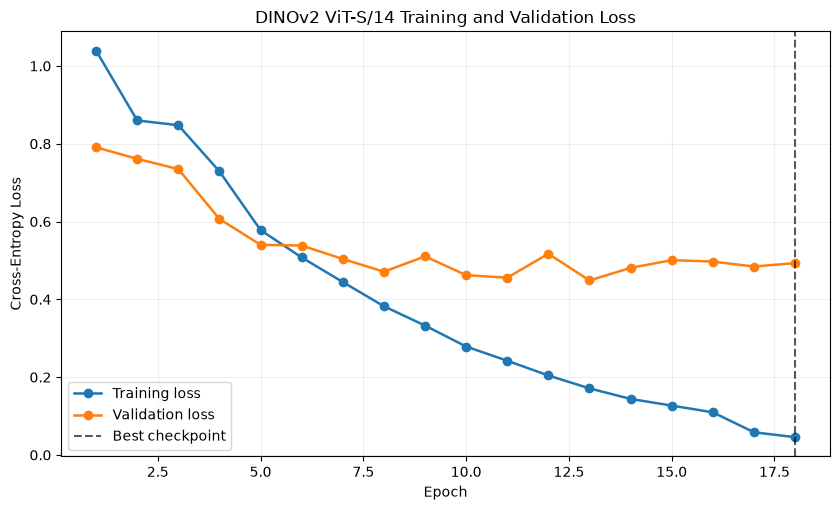

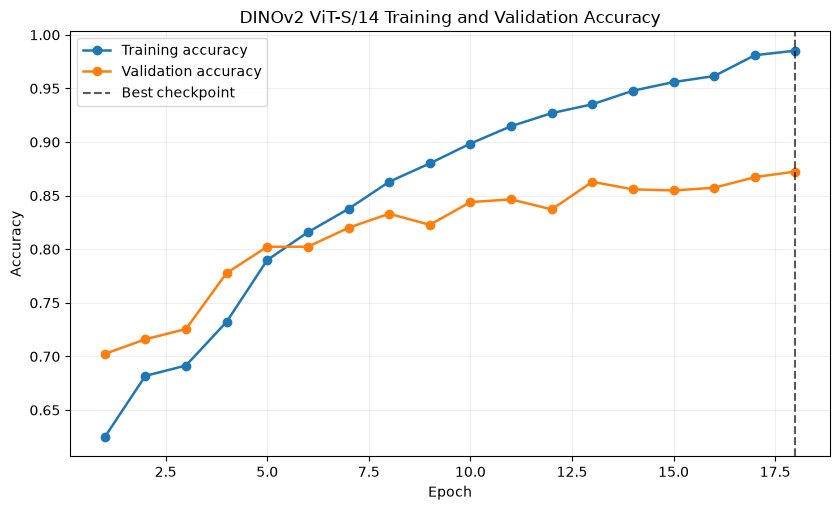

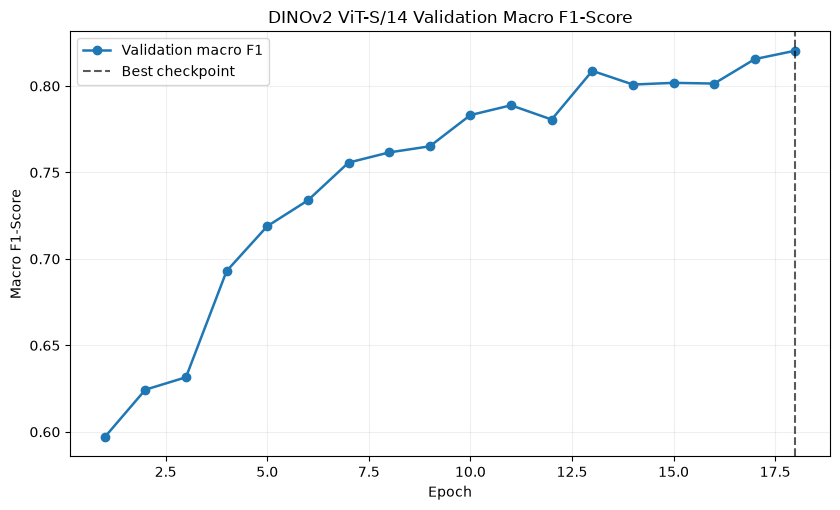

In [12]:
def save_curve(
    history_frame: pd.DataFrame,
    columns: list[str],
    labels: list[str],
    ylabel: str,
    title: str,
    output_path: Path,
) -> None:
    """Plot selected history columns and mark the checkpoint epoch."""
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    for column, label in zip(columns, labels):
        ax.plot(
            history_frame["epoch"],
            history_frame[column],
            marker="o",
            linewidth=1.8,
            label=label,
        )
    ax.axvline(
        best_epoch,
        color="black",
        linestyle="--",
        alpha=0.65,
        label="Best checkpoint",
    )
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.20)
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


save_curve(
    training_history,
    ["train_loss", "val_loss"],
    ["Training loss", "Validation loss"],
    "Cross-Entropy Loss",
    "DINOv2 ViT-S/14 Training and Validation Loss",
    FIGURES_DIR / "06_dinov2_loss_curve.png",
)
save_curve(
    training_history,
    ["train_accuracy", "val_accuracy"],
    ["Training accuracy", "Validation accuracy"],
    "Accuracy",
    "DINOv2 ViT-S/14 Training and Validation Accuracy",
    FIGURES_DIR / "06_dinov2_accuracy_curve.png",
)
save_curve(
    training_history,
    ["val_macro_f1"],
    ["Validation macro F1"],
    "Macro F1-Score",
    "DINOv2 ViT-S/14 Validation Macro F1-Score",
    FIGURES_DIR / "06_dinov2_macro_f1_curve.png",
)


## 13. Best-Checkpoint Validation Evaluation

The macro-F1-selected checkpoint is reloaded before all subsequent validation analysis. Overall and per-class results use the same schemas as the three CNN baselines.


In [13]:
checkpoint = load_model_checkpoint(CHECKPOINT_PATH, model, DEVICE)

if checkpoint["class_mapping"] != CLASS_ID_TO_NAME:
    raise ValueError(
        "The checkpoint class mapping differs from the active manifest mapping."
    )
if checkpoint["architecture"] != "DINOv2 ViT-S/14":
    raise ValueError("The checkpoint architecture metadata is inconsistent.")
if checkpoint["image_size"] != IMAGE_SIZE:
    raise ValueError("The checkpoint image size differs from the active pipeline.")

best_validation = evaluate_model(
    model,
    validation_loader,
    criterion,
    DEVICE,
    description="Best-checkpoint validation",
)
expected_validation_paths = manifests["validation"]["relative_path"].tolist()
if best_validation["relative_paths"] != expected_validation_paths:
    raise ValueError("Validation prediction order differs from the manifest order.")

validation_targets = best_validation["targets"]
validation_predictions = best_validation["predictions"]
validation_metric_values = {
    "accuracy": accuracy_score(validation_targets, validation_predictions),
    "balanced_accuracy": balanced_accuracy_score(
        validation_targets, validation_predictions
    ),
    "macro_f1": f1_score(
        validation_targets,
        validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "macro_precision": precision_score(
        validation_targets,
        validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "macro_recall": recall_score(
        validation_targets,
        validation_predictions,
        average="macro",
        zero_division=0,
    ),
    "weighted_f1": f1_score(
        validation_targets,
        validation_predictions,
        average="weighted",
        zero_division=0,
    ),
}
validation_metrics_table = pd.DataFrame(
    {
        "metric": list(validation_metric_values),
        "value": list(validation_metric_values.values()),
    }
)
validation_metrics_table.to_csv(
    REPORTS_DIR / "06_dinov2_validation_metrics.csv",
    index=False,
    encoding="utf-8",
)

class_ids = class_mapping_table["class_id"].to_numpy()
per_class_precision, per_class_recall, per_class_f1, per_class_support = (
    precision_recall_fscore_support(
        validation_targets,
        validation_predictions,
        labels=class_ids,
        zero_division=0,
    )
)
per_class_metrics = pd.DataFrame(
    {
        "class_id": class_ids,
        "class_name": [
            CLASS_ID_TO_NAME[int(class_id)] for class_id in class_ids
        ],
        "precision": per_class_precision,
        "recall": per_class_recall,
        "f1_score": per_class_f1,
        "support": per_class_support.astype(int),
    }
)
per_class_metrics.to_csv(
    REPORTS_DIR / "06_dinov2_per_class_metrics.csv",
    index=False,
    encoding="utf-8",
)

print(
    f"Loaded best checkpoint from epoch {checkpoint['epoch']} "
    f"({checkpoint['stage']})."
)
display(validation_metrics_table.style.format({"value": "{:.4f}"}))
display(
    per_class_metrics.style.format(
        {
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1_score": "{:.4f}",
            "support": "{:,}",
        }
    )
)


Best-checkpoint validation:   0%|          | 0/248 [00:00<?, ?batch/s]

Loaded best checkpoint from epoch 18 (partial_fine_tuning).


,metric,value
0,accuracy,0.8725
1,balanced_accuracy,0.8211
2,macro_f1,0.8204
3,macro_precision,0.8244
4,macro_recall,0.8211
5,weighted_f1,0.8716


,class_id,class_name,precision,recall,f1_score,support
0,0,Eczema,0.6531,0.7763,0.7094,228
1,1,Melanoma,0.9912,0.9533,0.9719,471
2,2,Atopic Dermatitis,0.6802,0.6842,0.6822,171
3,3,Basal Cell Carcinoma (BCC),0.9120,0.9598,0.9353,497
4,4,Melanocytic Nevi (NV),0.9530,0.9665,0.9597,"1,195"
5,5,Benign Keratosis-like Lesions (BKL),0.8660,0.8129,0.8386,310
6,6,Psoriasis / Lichen Planus / Related Diseases,0.7946,0.6096,0.6899,292
7,7,Seborrheic Keratoses / Other Benign Tumors,0.8167,0.8974,0.8551,273
8,8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,0.7423,0.7878,0.7644,245
9,9,Warts / Molluscum / Other Viral Infections,0.8353,0.7634,0.7978,279


## 14. Confusion Matrices

The raw matrix reports validation image counts. Row normalization reports the prediction distribution within each true class and therefore exposes class-level recall patterns.


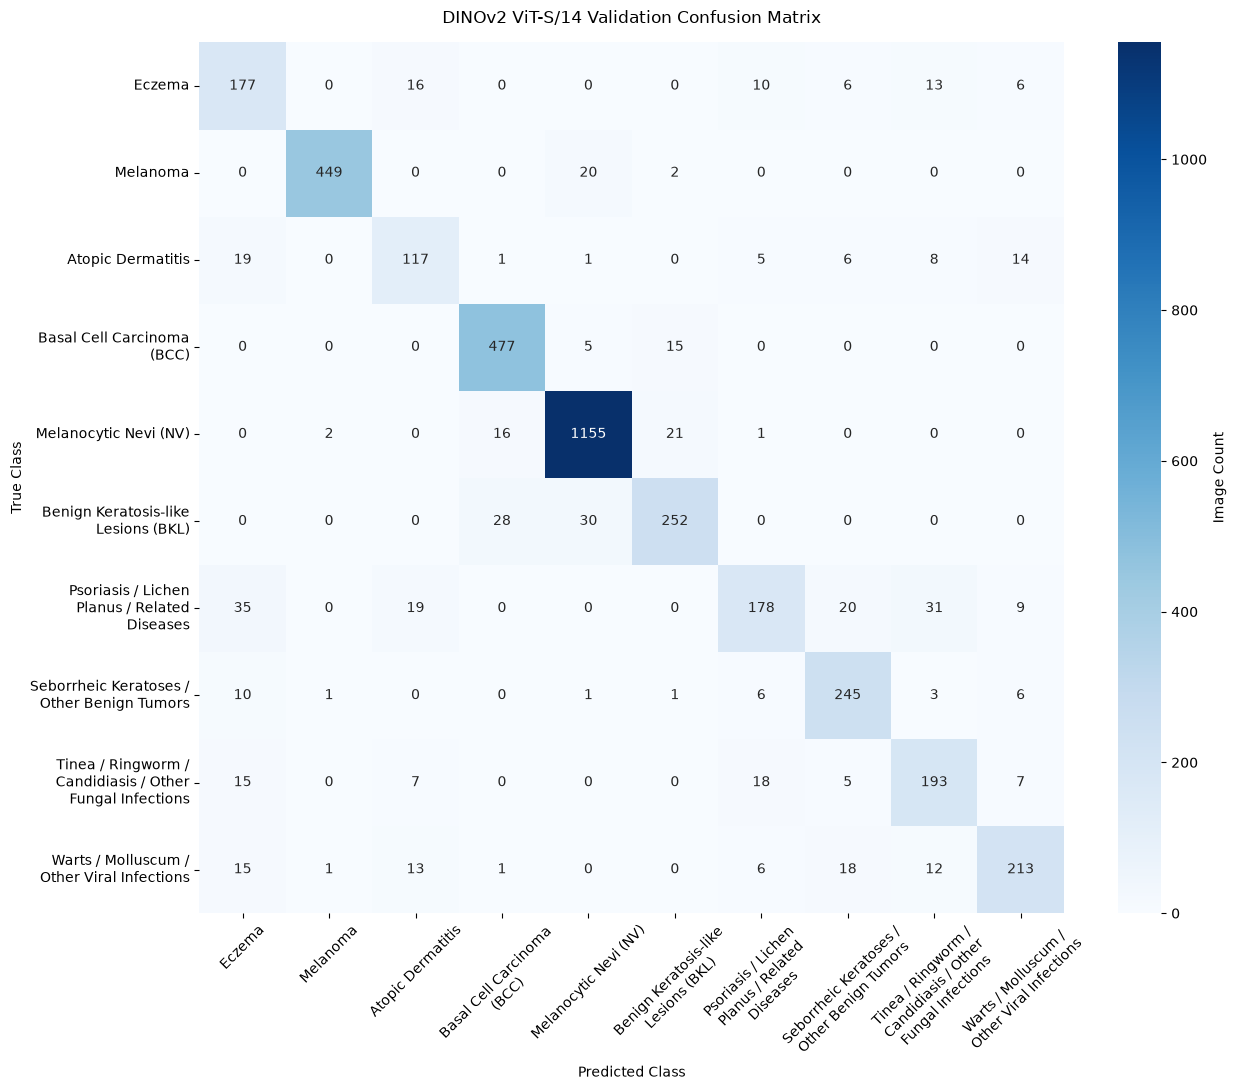

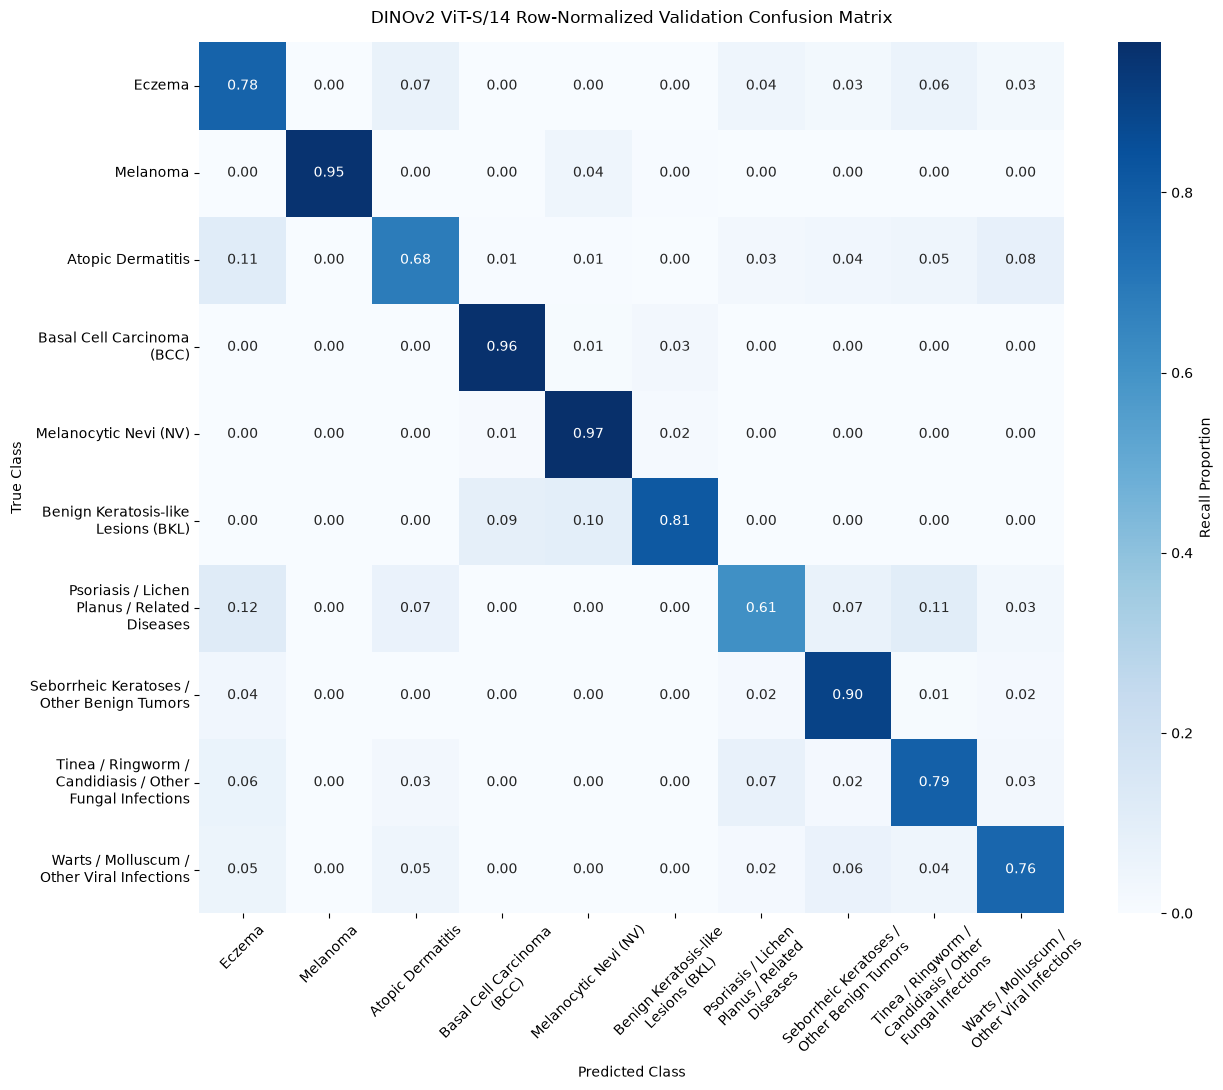

In [14]:
raw_confusion_matrix = confusion_matrix(
    validation_targets, validation_predictions, labels=class_ids
)
normalized_confusion_matrix = confusion_matrix(
    validation_targets,
    validation_predictions,
    labels=class_ids,
    normalize="true",
)
display_labels = [
    textwrap.fill(CLASS_ID_TO_NAME[int(class_id)], width=24)
    for class_id in class_ids
]


def plot_confusion_matrix(
    matrix,
    title: str,
    output_path: Path,
    value_format: str,
    colorbar_label: str,
) -> None:
    """Save a labeled validation confusion matrix."""
    fig, ax = plt.subplots(figsize=(13, 11))
    sns.heatmap(
        matrix,
        annot=True,
        fmt=value_format,
        cmap="Blues",
        xticklabels=display_labels,
        yticklabels=display_labels,
        cbar_kws={"label": colorbar_label},
        ax=ax,
    )
    ax.set_title(title, pad=14)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


plot_confusion_matrix(
    raw_confusion_matrix,
    "DINOv2 ViT-S/14 Validation Confusion Matrix",
    FIGURES_DIR / "06_dinov2_confusion_matrix.png",
    "d",
    "Image Count",
)
plot_confusion_matrix(
    normalized_confusion_matrix,
    "DINOv2 ViT-S/14 Row-Normalized Validation Confusion Matrix",
    FIGURES_DIR / "06_dinov2_confusion_matrix_normalized.png",
    ".2f",
    "Recall Proportion",
)


## 15. Error Analysis

Recall and F1 extrema and the most frequent directed confusions are reported descriptively. These patterns do not justify unsupported clinical explanations.


In [15]:
highest_recall_row = per_class_metrics.loc[per_class_metrics["recall"].idxmax()]
lowest_recall_row = per_class_metrics.loc[per_class_metrics["recall"].idxmin()]
highest_f1_row = per_class_metrics.loc[per_class_metrics["f1_score"].idxmax()]
lowest_f1_row = per_class_metrics.loc[per_class_metrics["f1_score"].idxmin()]

off_diagonal_confusions = raw_confusion_matrix.copy()
np.fill_diagonal(off_diagonal_confusions, 0)
confusion_records = []
for true_index, predicted_index in zip(
    *np.where(off_diagonal_confusions > 0)
):
    confusion_records.append(
        {
            "true_class": CLASS_ID_TO_NAME[int(class_ids[true_index])],
            "predicted_class": CLASS_ID_TO_NAME[
                int(class_ids[predicted_index])
            ],
            "image_count": int(
                off_diagonal_confusions[true_index, predicted_index]
            ),
        }
    )
frequent_confusions = pd.DataFrame(
    confusion_records,
    columns=["true_class", "predicted_class", "image_count"],
).sort_values(
    ["image_count", "true_class", "predicted_class"],
    ascending=[False, True, True],
    ignore_index=True,
)
if frequent_confusions.empty:
    most_common_confusion = {
        "true_class": "none",
        "predicted_class": "none",
        "image_count": 0,
    }
else:
    most_common_confusion = frequent_confusions.iloc[0]

print(
    f"Highest validation recall: {highest_recall_row['class_name']} "
    f"({highest_recall_row['recall']:.4f})"
)
print(
    f"Lowest validation recall: {lowest_recall_row['class_name']} "
    f"({lowest_recall_row['recall']:.4f})"
)
print(
    f"Highest validation F1: {highest_f1_row['class_name']} "
    f"({highest_f1_row['f1_score']:.4f})"
)
print(
    f"Lowest validation F1: {lowest_f1_row['class_name']} "
    f"({lowest_f1_row['f1_score']:.4f})"
)
print("Most frequent directed confusion pairs:")
display(frequent_confusions.head(10))


Highest validation recall: Melanocytic Nevi (NV) (0.9665)
Lowest validation recall: Psoriasis / Lichen Planus / Related Diseases (0.6096)
Highest validation F1: Melanoma (0.9719)
Lowest validation F1: Atopic Dermatitis (0.6822)
Most frequent directed confusion pairs:


,true_class,predicted_class,image_count
0,Psoriasis / Lichen Planus / Related Diseases,Eczema,35
1,Psoriasis / Lichen Planus / Related Diseases,Tinea / Ringworm / Candidiasis / Other Fungal ...,31
2,Benign Keratosis-like Lesions (BKL),Melanocytic Nevi (NV),30
3,Benign Keratosis-like Lesions (BKL),Basal Cell Carcinoma (BCC),28
4,Melanocytic Nevi (NV),Benign Keratosis-like Lesions (BKL),21
5,Melanoma,Melanocytic Nevi (NV),20
6,Psoriasis / Lichen Planus / Related Diseases,Seborrheic Keratoses / Other Benign Tumors,20
7,Atopic Dermatitis,Eczema,19
8,Psoriasis / Lichen Planus / Related Diseases,Atopic Dermatitis,19
9,Tinea / Ringworm / Candidiasis / Other Fungal ...,Psoriasis / Lichen Planus / Related Diseases,18


## 16. Confidence Analysis and Validation Prediction Output

The complete validation prediction table includes hard predictions, maximum softmax confidence, and one probability column per class. It supports later ensemble, disagreement, and poster analysis without retraining DINOv2. Softmax confidence is not treated as calibrated probability or clinical certainty.


Average confidence for correct predictions: 0.9646
Average confidence for incorrect predictions: 0.7938
Saved validation predictions: C:\Projekt konferencyjny Turcja\skin-disease-classification\reports\predictions\06_dinov2_validation_predictions.csv


,example_type,relative_path,true_class,predicted_class,confidence
0,High-confidence correct,data/raw/skin-diseases-image-dataset/IMG_CLASSES/2. Melanoma 15.75k/ISIC_6652978.jpg,Melanoma,Melanoma,1.0000
1,High-confidence correct,data/raw/skin-diseases-image-dataset/IMG_CLASSES/2. Melanoma 15.75k/ISIC_6662824.jpg,Melanoma,Melanoma,1.0000
2,High-confidence correct,data/raw/skin-diseases-image-dataset/IMG_CLASSES/2. Melanoma 15.75k/ISIC_6665515.jpg,Melanoma,Melanoma,1.0000
3,High-confidence correct,data/raw/skin-diseases-image-dataset/IMG_CLASSES/2. Melanoma 15.75k/ISIC_6666329.jpg,Melanoma,Melanoma,1.0000
4,High-confidence incorrect,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/6_80.jpg,Atopic Dermatitis,Warts / Molluscum / Other Viral Infections,1.0000
5,High-confidence incorrect,data/raw/skin-diseases-image-dataset/IMG_CLASSES/10. Warts Molluscum and other Viral Infections - 2103/t-warts-flat-55.jpg,Warts / Molluscum / Other Viral Infections,Seborrheic Keratoses / Other Benign Tumors,1.0000
6,High-confidence incorrect,data/raw/skin-diseases-image-dataset/IMG_CLASSES/3. Atopic Dermatitis - 1.25k/t-9IMG012.jpg,Atopic Dermatitis,Eczema,1.0000
7,High-confidence incorrect,data/raw/skin-diseases-image-dataset/IMG_CLASSES/1. Eczema 1677/t-fiberglass-dermatitis-5.jpg,Eczema,Seborrheic Keratoses / Other Benign Tumors,1.0000


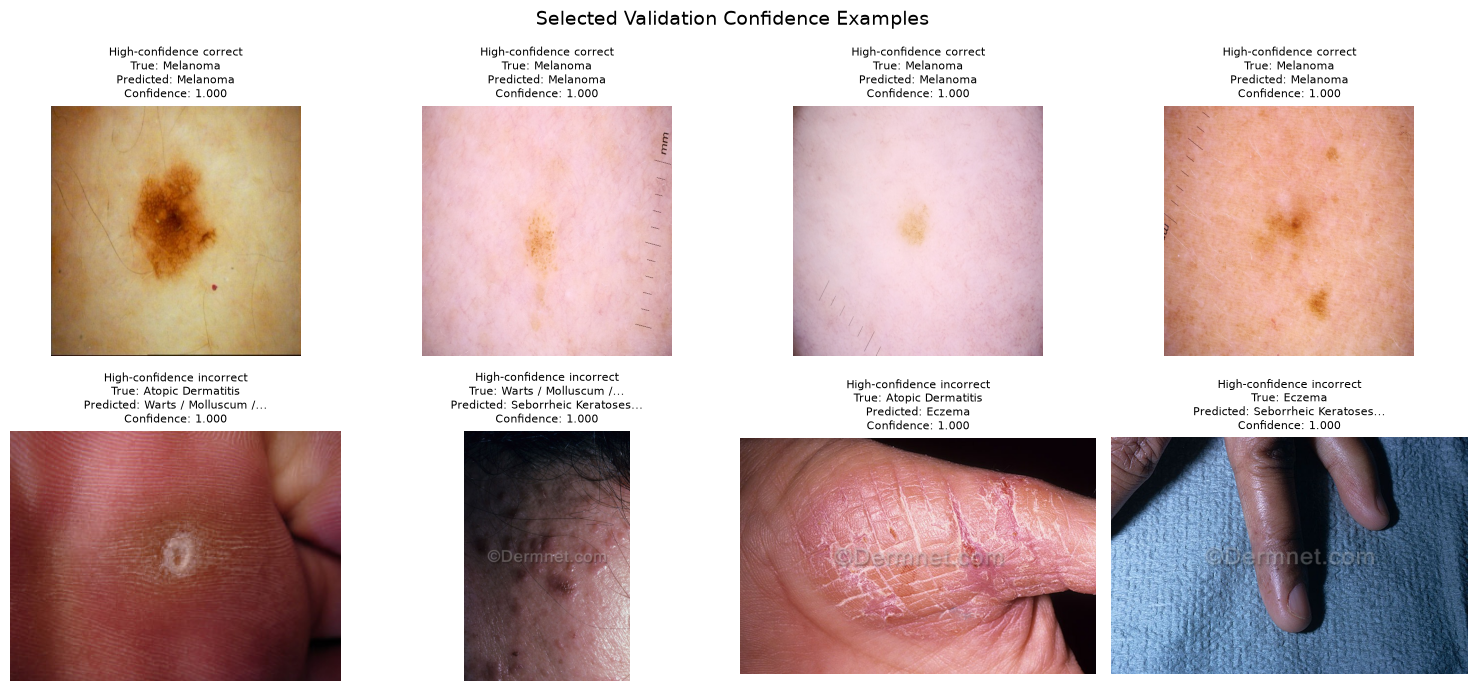

In [16]:
validation_predictions_table = pd.DataFrame(
    {
        "relative_path": best_validation["relative_paths"],
        "true_class_id": validation_targets,
        "true_class": [
            CLASS_ID_TO_NAME[int(class_id)] for class_id in validation_targets
        ],
        "predicted_class_id": validation_predictions,
        "predicted_class": [
            CLASS_ID_TO_NAME[int(class_id)]
            for class_id in validation_predictions
        ],
        "confidence": best_validation["confidences"],
        "correct": validation_targets == validation_predictions,
    }
)
for probability_index, class_id in enumerate(class_ids):
    validation_predictions_table[f"prob_class_{int(class_id)}"] = (
        best_validation["probabilities"][:, probability_index]
    )

PREDICTIONS_PATH = (
    PREDICTIONS_DIR / "06_dinov2_validation_predictions.csv"
)
validation_predictions_table.to_csv(
    PREDICTIONS_PATH, index=False, encoding="utf-8"
)

correct_confidence = validation_predictions_table.loc[
    validation_predictions_table["correct"], "confidence"
].mean()
incorrect_confidence = validation_predictions_table.loc[
    ~validation_predictions_table["correct"], "confidence"
].mean()

print(f"Average confidence for correct predictions: {correct_confidence:.4f}")
print(f"Average confidence for incorrect predictions: {incorrect_confidence:.4f}")
print(f"Saved validation predictions: {PREDICTIONS_PATH}")

confidence_examples = pd.concat(
    [
        validation_predictions_table.loc[
            validation_predictions_table["correct"]
        ]
        .nlargest(4, "confidence")
        .assign(example_type="High-confidence correct"),
        validation_predictions_table.loc[
            ~validation_predictions_table["correct"]
        ]
        .nlargest(4, "confidence")
        .assign(example_type="High-confidence incorrect"),
    ],
    ignore_index=True,
)
display(
    confidence_examples[
        [
            "example_type",
            "relative_path",
            "true_class",
            "predicted_class",
            "confidence",
        ]
    ].style.format({"confidence": "{:.4f}"})
)

fig, axes = plt.subplots(2, 4, figsize=(15, 7), squeeze=False)
for axis, (_, row) in zip(axes.flat, confidence_examples.iterrows()):
    with Image.open(PROJECT_ROOT / row["relative_path"]) as image:
        image_for_display = ImageOps.exif_transpose(image).convert("RGB")
        axis.imshow(image_for_display)
    axis.set_title(
        f"{row['example_type']}\n"
        f"True: {textwrap.shorten(row['true_class'], 24, placeholder='...')}\n"
        f"Predicted: "
        f"{textwrap.shorten(row['predicted_class'], 24, placeholder='...')}\n"
        f"Confidence: {row['confidence']:.3f}",
        fontsize=8,
    )
    axis.axis("off")
for axis in axes.flat[len(confidence_examples):]:
    axis.axis("off")
fig.suptitle("Selected Validation Confidence Examples", fontsize=14)
fig.tight_layout()
plt.show()


## 17. Overfitting and Generalization Analysis

The training-validation accuracy gap is calculated at the selected checkpoint. Validation loss progression, macro-F1 progression, class-level F1 variation, and the association between validation support and F1 are treated as descriptive indicators rather than causal evidence.


In [17]:
selected_history = training_history.loc[
    training_history["epoch"] == checkpoint["epoch"]
]
if len(selected_history) != 1:
    raise ValueError(
        "The selected checkpoint epoch is not unique in the training history."
    )

best_history_row = selected_history.iloc[0]
first_history_row = training_history.iloc[0]
last_history_row = training_history.iloc[-1]
minimum_validation_loss_row = training_history.loc[
    training_history["val_loss"].idxmin()
]

training_validation_gap = (
    best_history_row["train_accuracy"] - validation_metric_values["accuracy"]
)
per_class_f1_range = (
    per_class_metrics["f1_score"].max()
    - per_class_metrics["f1_score"].min()
)
support_f1_spearman = per_class_metrics["support"].corr(
    per_class_metrics["f1_score"], method="spearman"
)

generalization_indicators = pd.DataFrame(
    {
        "indicator": [
            "Training-validation accuracy gap at selected checkpoint",
            "Per-class F1 range",
            "Spearman correlation: validation support vs. F1",
        ],
        "value": [
            training_validation_gap,
            per_class_f1_range,
            support_f1_spearman,
        ],
    }
)
display(generalization_indicators.style.format({"value": "{:.4f}"}))

if training_validation_gap > 0.10:
    fit_interpretation = (
        "The selected checkpoint has a notable positive accuracy gap, which is "
        "compatible with overfitting pressure."
    )
elif training_validation_gap > 0.03:
    fit_interpretation = (
        "The selected checkpoint has a modest positive accuracy gap, indicating "
        "some overfitting pressure."
    )
else:
    fit_interpretation = (
        "The selected checkpoint does not show a large positive accuracy gap."
    )

if pd.isna(support_f1_spearman):
    support_interpretation = (
        "The support-F1 rank correlation is undefined for the observed values."
    )
elif abs(support_f1_spearman) <= 0.30:
    support_interpretation = (
        "The rank association between validation support and F1 is weak."
    )
elif support_f1_spearman > 0:
    support_interpretation = (
        "Validation support and F1 show a positive rank association."
    )
else:
    support_interpretation = (
        "Validation support and F1 show a negative rank association."
    )

interpretation_markdown = f"""
At the selected epoch, training accuracy was {best_history_row['train_accuracy']:.4f} and validation accuracy was {validation_metric_values['accuracy']:.4f}, producing a gap of {training_validation_gap:+.4f}. {fit_interpretation}

Per-class F1 spans {per_class_f1_range:.4f}; the Spearman correlation between validation support and F1 is {support_f1_spearman:.4f}. {support_interpretation} These statistics describe one fixed validation subset and do not imply that class frequency causes the observed differences.

Validation loss reached its minimum of {minimum_validation_loss_row['val_loss']:.4f} at epoch {int(minimum_validation_loss_row['epoch'])}. The final recorded validation loss was {last_history_row['val_loss']:.4f}. Validation selection, softmax confidence, and the present split do not establish external generalization or clinical diagnostic reliability.
"""
display(Markdown(interpretation_markdown))


,indicator,value
0,Training-validation accuracy gap at selected checkpoint,0.1127
1,Per-class F1 range,0.2896
2,Spearman correlation: validation support vs. F1,0.7939



At the selected epoch, training accuracy was 0.9852 and validation accuracy was 0.8725, producing a gap of +0.1127. The selected checkpoint has a notable positive accuracy gap, which is compatible with overfitting pressure.

Per-class F1 spans 0.2896; the Spearman correlation between validation support and F1 is 0.7939. Validation support and F1 show a positive rank association. These statistics describe one fixed validation subset and do not imply that class frequency causes the observed differences.

Validation loss reached its minimum of 0.4486 at epoch 13. The final recorded validation loss was 0.4932. Validation selection, softmax confidence, and the present split do not establish external generalization or clinical diagnostic reliability.


## 18. Four-Model Architecture Comparison

ResNet50, EfficientNetV2-S, ConvNeXt-Tiny, and DINOv2 ViT-S/14 metrics are loaded from their saved reports. No earlier numerical result is hardcoded. The table retains all six aggregate metrics, while the figure focuses on accuracy, balanced accuracy, and macro F1.


,architecture,accuracy,balanced_accuracy,macro_f1,macro_precision,macro_recall,weighted_f1
0,ResNet50,0.8533,0.7885,0.7869,0.7869,0.7885,0.8533
1,EfficientNetV2-S,0.8892,0.8327,0.8319,0.8349,0.8327,0.8902
2,ConvNeXt-Tiny,0.8846,0.8283,0.8265,0.8288,0.8283,0.8850
3,DINOv2 ViT-S/14,0.8725,0.8211,0.8204,0.8244,0.8211,0.8716


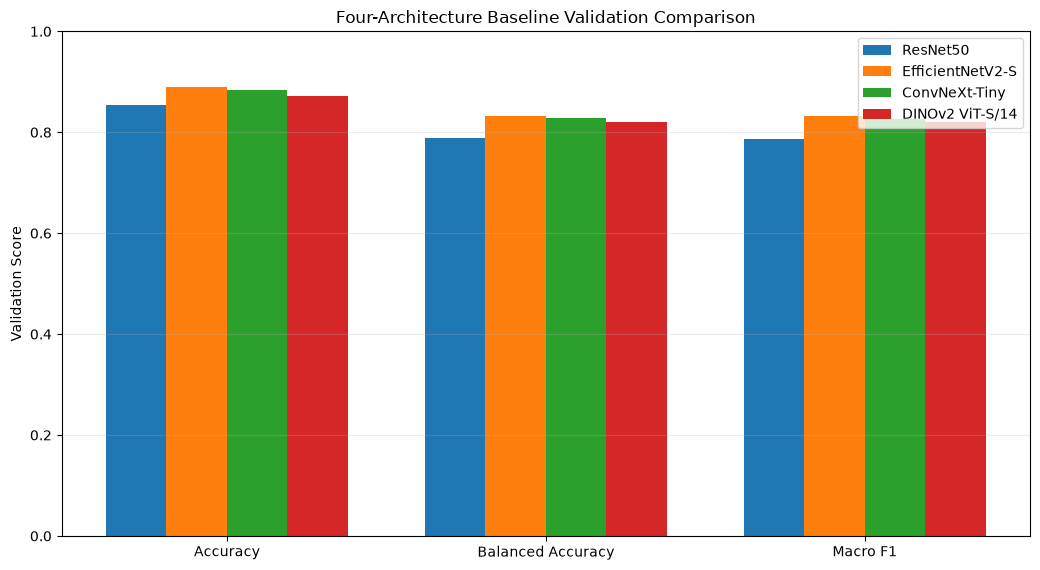

,architecture,selected_epoch,training_validation_accuracy_gap
0,ResNet50,19,+0.1294
1,EfficientNetV2-S,20,+0.1044
2,ConvNeXt-Tiny,17,+0.1113
3,DINOv2 ViT-S/14,18,+0.1127


In [18]:
ARCHITECTURE_REPORTS = {
    "ResNet50": {
        "metrics": REPORTS_DIR / "03_resnet50_validation_metrics.csv",
        "per_class": REPORTS_DIR / "03_resnet50_per_class_metrics.csv",
        "history": REPORTS_DIR / "03_resnet50_training_history.csv",
    },
    "EfficientNetV2-S": {
        "metrics": REPORTS_DIR / "04_efficientnetv2_validation_metrics.csv",
        "per_class": REPORTS_DIR / "04_efficientnetv2_per_class_metrics.csv",
        "history": REPORTS_DIR / "04_efficientnetv2_training_history.csv",
    },
    "ConvNeXt-Tiny": {
        "metrics": REPORTS_DIR / "05_convnext_tiny_validation_metrics.csv",
        "per_class": REPORTS_DIR / "05_convnext_tiny_per_class_metrics.csv",
        "history": REPORTS_DIR / "05_convnext_tiny_training_history.csv",
    },
    "DINOv2 ViT-S/14": {
        "metrics": REPORTS_DIR / "06_dinov2_validation_metrics.csv",
        "per_class": REPORTS_DIR / "06_dinov2_per_class_metrics.csv",
        "history": REPORTS_DIR / "06_dinov2_training_history.csv",
    },
}
missing_architecture_reports = [
    path
    for reports in ARCHITECTURE_REPORTS.values()
    for path in reports.values()
    if not path.is_file()
]
if missing_architecture_reports:
    missing_text = "\n".join(
        f"  - {path}" for path in missing_architecture_reports
    )
    raise FileNotFoundError(
        "Architecture comparison reports are missing:\n" f"{missing_text}"
    )

COMPARISON_METRICS = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "macro_precision",
    "macro_recall",
    "weighted_f1",
]


def load_metric_report(path: Path) -> pd.Series:
    """Load and validate a metric,value report."""
    report = pd.read_csv(path)
    if list(report.columns) != ["metric", "value"]:
        raise ValueError(f"Unexpected overall metric schema in {path.name}.")
    if report["metric"].duplicated().any():
        raise ValueError(f"Duplicate metric names exist in {path.name}.")
    values = report.set_index("metric")["value"].astype(float)
    missing_metrics = [
        metric for metric in COMPARISON_METRICS if metric not in values.index
    ]
    if missing_metrics:
        raise ValueError(
            f"{path.name} is missing comparison metrics: {missing_metrics}"
        )
    return values


architecture_metric_series = {
    architecture: load_metric_report(reports["metrics"])
    for architecture, reports in ARCHITECTURE_REPORTS.items()
}
architecture_comparison = pd.DataFrame(
    [
        {
            "architecture": architecture,
            **{
                metric: metric_values[metric]
                for metric in COMPARISON_METRICS
            },
        }
        for architecture, metric_values in architecture_metric_series.items()
    ]
)
architecture_comparison.to_csv(
    REPORTS_DIR / "06_architecture_baseline_comparison.csv",
    index=False,
    encoding="utf-8",
)
display(
    architecture_comparison.style.format(
        {metric: "{:.4f}" for metric in COMPARISON_METRICS}
    )
)

main_metrics = ["accuracy", "balanced_accuracy", "macro_f1"]
main_metric_labels = ["Accuracy", "Balanced Accuracy", "Macro F1"]
x_positions = np.arange(len(main_metrics))
bar_width = 0.19

fig, ax = plt.subplots(figsize=(10.5, 5.8))
center_offset = (len(architecture_comparison) - 1) / 2
for model_index, row in architecture_comparison.iterrows():
    offset = (model_index - center_offset) * bar_width
    ax.bar(
        x_positions + offset,
        row[main_metrics].astype(float),
        width=bar_width,
        label=row["architecture"],
    )
ax.set_xticks(x_positions, main_metric_labels)
ax.set_ylim(0, 1)
ax.set_ylabel("Validation Score")
ax.set_title("Four-Architecture Baseline Validation Comparison")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "06_architecture_baseline_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

generalization_gap_records = []
for architecture, reports in ARCHITECTURE_REPORTS.items():
    history_report = pd.read_csv(reports["history"])
    required_history_columns = {
        "epoch",
        "train_accuracy",
        "val_accuracy",
        "val_macro_f1",
    }
    missing_columns = required_history_columns - set(history_report.columns)
    if missing_columns:
        raise ValueError(
            f"{reports['history'].name} is missing columns: "
            f"{sorted(missing_columns)}"
        )
    selected_row = history_report.loc[history_report["val_macro_f1"].idxmax()]
    reported_accuracy = architecture_metric_series[architecture]["accuracy"]
    generalization_gap_records.append(
        {
            "architecture": architecture,
            "selected_epoch": int(selected_row["epoch"]),
            "training_validation_accuracy_gap": (
                float(selected_row["train_accuracy"]) - reported_accuracy
            ),
        }
    )
generalization_gap_comparison = pd.DataFrame(generalization_gap_records)
display(
    generalization_gap_comparison.style.format(
        {"training_validation_accuracy_gap": "{:+.4f}"}
    )
)


## 19. Per-Class Four-Model Comparison

Per-class F1 reports are joined by class identifier and name. The best CNN score provides a direct reference for DINOv2. A difference of at least 0.05 is used as a descriptive threshold for a substantial DINOv2 improvement; smaller differences remain visible but are not overinterpreted.


In [19]:
EXPECTED_PER_CLASS_COLUMNS = {
    "class_id",
    "class_name",
    "precision",
    "recall",
    "f1_score",
    "support",
}


def load_per_class_report(path: Path, f1_column_name: str) -> pd.DataFrame:
    """Load a per-class report and retain validated identifiers and F1."""
    report = pd.read_csv(path)
    if set(report.columns) != EXPECTED_PER_CLASS_COLUMNS:
        raise ValueError(f"Unexpected per-class metric schema in {path.name}.")
    if report[["class_id", "class_name"]].duplicated().any():
        raise ValueError(f"Duplicate class rows exist in {path.name}.")
    return report[["class_id", "class_name", "f1_score"]].rename(
        columns={"f1_score": f1_column_name}
    )


per_class_architecture_comparison = load_per_class_report(
    ARCHITECTURE_REPORTS["ResNet50"]["per_class"], "resnet50_f1"
)
per_class_architecture_comparison = per_class_architecture_comparison.merge(
    load_per_class_report(
        ARCHITECTURE_REPORTS["EfficientNetV2-S"]["per_class"],
        "efficientnetv2_s_f1",
    ),
    on=["class_id", "class_name"],
    how="inner",
    validate="one_to_one",
)
per_class_architecture_comparison = per_class_architecture_comparison.merge(
    load_per_class_report(
        ARCHITECTURE_REPORTS["ConvNeXt-Tiny"]["per_class"],
        "convnext_tiny_f1",
    ),
    on=["class_id", "class_name"],
    how="inner",
    validate="one_to_one",
)
per_class_architecture_comparison = per_class_architecture_comparison.merge(
    load_per_class_report(
        ARCHITECTURE_REPORTS["DINOv2 ViT-S/14"]["per_class"],
        "dinov2_vits14_f1",
    ),
    on=["class_id", "class_name"],
    how="inner",
    validate="one_to_one",
)
if len(per_class_architecture_comparison) != NUM_CLASSES:
    raise ValueError(
        "The four architecture reports do not share the complete class mapping."
    )
per_class_architecture_comparison = per_class_architecture_comparison.merge(
    per_class_metrics[["class_id", "class_name", "support"]],
    on=["class_id", "class_name"],
    how="inner",
    validate="one_to_one",
)

f1_columns = [
    "resnet50_f1",
    "efficientnetv2_s_f1",
    "convnext_tiny_f1",
    "dinov2_vits14_f1",
]
f1_to_architecture = {
    "resnet50_f1": "ResNet50",
    "efficientnetv2_s_f1": "EfficientNetV2-S",
    "convnext_tiny_f1": "ConvNeXt-Tiny",
    "dinov2_vits14_f1": "DINOv2 ViT-S/14",
}
per_class_architecture_comparison["best_cnn_f1"] = (
    per_class_architecture_comparison[
        ["resnet50_f1", "efficientnetv2_s_f1", "convnext_tiny_f1"]
    ].max(axis=1)
)
per_class_architecture_comparison["dinov2_vs_best_cnn_f1"] = (
    per_class_architecture_comparison["dinov2_vits14_f1"]
    - per_class_architecture_comparison["best_cnn_f1"]
)
per_class_architecture_comparison["best_architecture"] = (
    per_class_architecture_comparison[f1_columns]
    .idxmax(axis=1)
    .map(f1_to_architecture)
)
per_class_architecture_comparison.to_csv(
    REPORTS_DIR / "06_architecture_per_class_f1.csv",
    index=False,
    encoding="utf-8",
)

class_wins = (
    per_class_architecture_comparison["best_architecture"]
    .value_counts()
    .reindex(list(f1_to_architecture.values()), fill_value=0)
    .rename_axis("architecture")
    .reset_index(name="classes_won")
)
SUBSTANTIAL_F1_DIFFERENCE = 0.05
substantial_dinov2_improvements = per_class_architecture_comparison.loc[
    per_class_architecture_comparison["dinov2_vs_best_cnn_f1"]
    >= SUBSTANTIAL_F1_DIFFERENCE
].sort_values("dinov2_vs_best_cnn_f1", ascending=False)
dinov2_decreases = per_class_architecture_comparison.loc[
    per_class_architecture_comparison["dinov2_vs_best_cnn_f1"] < 0
].sort_values("dinov2_vs_best_cnn_f1")
minority_support_threshold = float(
    per_class_architecture_comparison["support"].median()
)
previously_difficult_class_ids = set(
    per_class_architecture_comparison.nsmallest(3, "best_cnn_f1")["class_id"]
)
minority_or_difficult_classes = per_class_architecture_comparison.loc[
    (per_class_architecture_comparison["support"] <= minority_support_threshold)
    | per_class_architecture_comparison["class_id"].isin(
        previously_difficult_class_ids
    )
].sort_values("dinov2_vs_best_cnn_f1", ascending=False)

display(
    per_class_architecture_comparison.style.format(
        {column: "{:.4f}" for column in f1_columns}
        | {
            "best_cnn_f1": "{:.4f}",
            "dinov2_vs_best_cnn_f1": "{:+.4f}",
        }
    )
)
print("Classes won by architecture (exact ties follow column order):")
display(class_wins)
print(
    f"DINOv2 improvements of at least {SUBSTANTIAL_F1_DIFFERENCE:.2f} "
    "over the best CNN:"
)
display(
    substantial_dinov2_improvements[
        [
            "class_name",
            "best_cnn_f1",
            "dinov2_vits14_f1",
            "dinov2_vs_best_cnn_f1",
        ]
    ].style.format(
        {
            "best_cnn_f1": "{:.4f}",
            "dinov2_vits14_f1": "{:.4f}",
            "dinov2_vs_best_cnn_f1": "{:+.4f}",
        }
    )
)
print("Classes where DINOv2 F1 is below the best CNN F1:")
display(
    dinov2_decreases[
        [
            "class_name",
            "best_cnn_f1",
            "dinov2_vits14_f1",
            "dinov2_vs_best_cnn_f1",
        ]
    ].style.format(
        {
            "best_cnn_f1": "{:.4f}",
            "dinov2_vits14_f1": "{:.4f}",
            "dinov2_vs_best_cnn_f1": "{:+.4f}",
        }
    )
)
print(
    "Lower-support or previously difficult classes and the DINOv2 change "
    "relative to the best CNN:"
)
display(
    minority_or_difficult_classes[
        [
            "class_name",
            "support",
            "best_cnn_f1",
            "dinov2_vits14_f1",
            "dinov2_vs_best_cnn_f1",
        ]
    ].style.format(
        {
            "support": "{:.0f}",
            "best_cnn_f1": "{:.4f}",
            "dinov2_vits14_f1": "{:.4f}",
            "dinov2_vs_best_cnn_f1": "{:+.4f}",
        }
    )
)


,class_id,class_name,resnet50_f1,efficientnetv2_s_f1,convnext_tiny_f1,dinov2_vits14_f1,support,best_cnn_f1,dinov2_vs_best_cnn_f1,best_architecture
0,0,Eczema,0.7009,0.7078,0.6994,0.7094,228,0.7078,+0.0017,DINOv2 ViT-S/14
1,1,Melanoma,0.9882,0.9947,0.9979,0.9719,471,0.9979,-0.0260,ConvNeXt-Tiny
2,2,Atopic Dermatitis,0.6331,0.6188,0.6431,0.6822,171,0.6431,+0.0391,DINOv2 ViT-S/14
3,3,Basal Cell Carcinoma (BCC),0.9388,0.9622,0.9616,0.9353,497,0.9622,-0.0269,EfficientNetV2-S
4,4,Melanocytic Nevi (NV),0.9694,0.9845,0.9802,0.9597,1195,0.9845,-0.0248,EfficientNetV2-S
5,5,Benign Keratosis-like Lesions (BKL),0.8357,0.8977,0.8864,0.8386,310,0.8977,-0.0591,EfficientNetV2-S
6,6,Psoriasis / Lichen Planus / Related Diseases,0.6542,0.7379,0.6899,0.6899,292,0.7379,-0.0480,EfficientNetV2-S
7,7,Seborrheic Keratoses / Other Benign Tumors,0.7700,0.8405,0.8346,0.8551,273,0.8405,+0.0146,DINOv2 ViT-S/14
8,8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,0.6851,0.7880,0.7592,0.7644,245,0.7880,-0.0237,EfficientNetV2-S
9,9,Warts / Molluscum / Other Viral Infections,0.6932,0.7870,0.8131,0.7978,279,0.8131,-0.0153,ConvNeXt-Tiny


Classes won by architecture (exact ties follow column order):


,architecture,classes_won
0,ResNet50,0
1,EfficientNetV2-S,5
2,ConvNeXt-Tiny,2
3,DINOv2 ViT-S/14,3


DINOv2 improvements of at least 0.05 over the best CNN:


,class_name,best_cnn_f1,dinov2_vits14_f1,dinov2_vs_best_cnn_f1


Classes where DINOv2 F1 is below the best CNN F1:


,class_name,best_cnn_f1,dinov2_vits14_f1,dinov2_vs_best_cnn_f1
5,Benign Keratosis-like Lesions (BKL),0.8977,0.8386,-0.0591
6,Psoriasis / Lichen Planus / Related Diseases,0.7379,0.6899,-0.0480
3,Basal Cell Carcinoma (BCC),0.9622,0.9353,-0.0269
1,Melanoma,0.9979,0.9719,-0.0260
4,Melanocytic Nevi (NV),0.9845,0.9597,-0.0248
8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,0.7880,0.7644,-0.0237
9,Warts / Molluscum / Other Viral Infections,0.8131,0.7978,-0.0153


Lower-support or previously difficult classes and the DINOv2 change relative to the best CNN:


,class_name,support,best_cnn_f1,dinov2_vits14_f1,dinov2_vs_best_cnn_f1
2,Atopic Dermatitis,171,0.6431,0.6822,+0.0391
7,Seborrheic Keratoses / Other Benign Tumors,273,0.8405,0.8551,+0.0146
0,Eczema,228,0.7078,0.7094,+0.0017
9,Warts / Molluscum / Other Viral Infections,279,0.8131,0.7978,-0.0153
8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,245,0.7880,0.7644,-0.0237
6,Psoriasis / Lichen Planus / Related Diseases,292,0.7379,0.6899,-0.0480


## 20. Model Disagreement Preparation

Existing validation prediction files are inventoried without rerunning previous models. When ConvNeXt-Tiny predictions are available, row-level disagreement with DINOv2 is summarized and saved for later ensemble analysis. Missing EfficientNetV2-S or ResNet50 prediction files are reported rather than regenerated in this notebook.


In [20]:
EXPECTED_PREDICTION_FILES = {
    "ResNet50": PREDICTIONS_DIR / "03_resnet50_validation_predictions.csv",
    "EfficientNetV2-S": (
        PREDICTIONS_DIR / "04_efficientnetv2_validation_predictions.csv"
    ),
    "ConvNeXt-Tiny": (
        PREDICTIONS_DIR / "05_convnext_tiny_validation_predictions.csv"
    ),
    "DINOv2 ViT-S/14": (
        PREDICTIONS_DIR / "06_dinov2_validation_predictions.csv"
    ),
}
prediction_file_availability = pd.DataFrame(
    [
        {
            "architecture": architecture,
            "prediction_file": path.relative_to(PROJECT_ROOT).as_posix(),
            "available": path.is_file(),
        }
        for architecture, path in EXPECTED_PREDICTION_FILES.items()
    ]
)
display(prediction_file_availability)

convnext_prediction_path = EXPECTED_PREDICTION_FILES["ConvNeXt-Tiny"]
dinov2_prediction_path = EXPECTED_PREDICTION_FILES["DINOv2 ViT-S/14"]
disagreement_summary = None

if convnext_prediction_path.is_file():
    required_prediction_columns = {
        "relative_path",
        "true_class_id",
        "predicted_class_id",
        "correct",
    }
    convnext_predictions = pd.read_csv(convnext_prediction_path)
    dinov2_predictions = pd.read_csv(dinov2_prediction_path)
    for architecture, table in {
        "ConvNeXt-Tiny": convnext_predictions,
        "DINOv2 ViT-S/14": dinov2_predictions,
    }.items():
        missing_columns = required_prediction_columns - set(table.columns)
        if missing_columns:
            raise ValueError(
                f"{architecture} prediction file is missing columns: "
                f"{sorted(missing_columns)}"
            )
        if table["relative_path"].duplicated().any():
            raise ValueError(
                f"{architecture} prediction file contains duplicate paths."
            )

    disagreement_table = convnext_predictions[
        [
            "relative_path",
            "true_class_id",
            "predicted_class_id",
            "correct",
        ]
    ].rename(
        columns={
            "predicted_class_id": "convnext_predicted_class_id",
            "correct": "convnext_correct",
        }
    ).merge(
        dinov2_predictions[
            [
                "relative_path",
                "true_class_id",
                "predicted_class_id",
                "correct",
            ]
        ].rename(
            columns={
                "predicted_class_id": "dinov2_predicted_class_id",
                "correct": "dinov2_correct",
            }
        ),
        on=["relative_path", "true_class_id"],
        how="inner",
        validate="one_to_one",
    )
    if len(disagreement_table) != len(manifests["validation"]):
        raise ValueError(
            "DINOv2 and ConvNeXt-Tiny prediction files do not cover the full "
            "validation manifest."
        )

    for column in ["convnext_correct", "dinov2_correct"]:
        if disagreement_table[column].dtype != bool:
            converted = (
                disagreement_table[column]
                .astype(str)
                .str.strip()
                .str.lower()
                .map({"true": True, "false": False})
            )
            if converted.isna().any():
                raise ValueError(f"Could not parse Boolean values in {column}.")
            disagreement_table[column] = converted

    disagreement_table["prediction_disagreement"] = (
        disagreement_table["convnext_predicted_class_id"]
        != disagreement_table["dinov2_predicted_class_id"]
    )
    disagreement_table["outcome_group"] = np.select(
        [
            disagreement_table["convnext_correct"]
            & disagreement_table["dinov2_correct"],
            ~disagreement_table["convnext_correct"]
            & disagreement_table["dinov2_correct"],
            disagreement_table["convnext_correct"]
            & ~disagreement_table["dinov2_correct"],
        ],
        [
            "both_correct",
            "dinov2_only_correct",
            "convnext_only_correct",
        ],
        default="both_incorrect",
    )
    disagreement_table.to_csv(
        PREDICTIONS_DIR / "06_dinov2_vs_convnext_disagreement.csv",
        index=False,
        encoding="utf-8",
    )
    disagreement_summary = pd.DataFrame(
        {
            "indicator": [
                "Prediction disagreement rate",
                "Both correct",
                "DINOv2 only correct",
                "ConvNeXt-Tiny only correct",
                "Both incorrect",
            ],
            "value": [
                disagreement_table["prediction_disagreement"].mean(),
                (disagreement_table["outcome_group"] == "both_correct").mean(),
                (
                    disagreement_table["outcome_group"]
                    == "dinov2_only_correct"
                ).mean(),
                (
                    disagreement_table["outcome_group"]
                    == "convnext_only_correct"
                ).mean(),
                (
                    disagreement_table["outcome_group"] == "both_incorrect"
                ).mean(),
            ],
        }
    )
    display(disagreement_summary.style.format({"value": "{:.4f}"}))
else:
    print(
        "ConvNeXt-Tiny validation predictions are unavailable; row-level "
        "disagreement analysis was skipped."
    )

print(
    "Previous model inference was not executed. Missing prediction files can be "
    "created only by an explicitly isolated future inference step."
)


,architecture,prediction_file,available
0,ResNet50,reports/predictions/03_resnet50_validation_pre...,False
1,EfficientNetV2-S,reports/predictions/04_efficientnetv2_validati...,False
2,ConvNeXt-Tiny,reports/predictions/05_convnext_tiny_validatio...,True
3,DINOv2 ViT-S/14,reports/predictions/06_dinov2_validation_predi...,True


,indicator,value
0,Prediction disagreement rate,0.1401
1,Both correct,0.8205
2,DINOv2 only correct,0.0520
3,ConvNeXt-Tiny only correct,0.0641
4,Both incorrect,0.0634


Previous model inference was not executed. Missing prediction files can be created only by an explicitly isolated future inference step.


## 21. Test Set Policy

The test manifest was checked only for structure, mapping consistency, group separation, row count, and referenced files. It was not used to construct a loader, select a checkpoint, tune a decision, or calculate any predictive metric.


In [21]:
TEST_SET_PREDICTIONS_GENERATED = False
print(f"Test-set predictions generated: {TEST_SET_PREDICTIONS_GENERATED}")


Test-set predictions generated: False


## DINOv2 ViT-S/14 Baseline Summary

The following results are generated automatically from the selected validation checkpoint and saved reports.


In [22]:
most_common_confusion_text = (
    f"true {most_common_confusion['true_class']} predicted as "
    f"{most_common_confusion['predicted_class']} "
    f"({int(most_common_confusion['image_count'])} images)"
)
summary_markdown = f"""
- **Best checkpoint epoch:** {checkpoint['epoch']} ({checkpoint['stage'].replace('_', ' ')})
- **Validation accuracy:** {validation_metric_values['accuracy']:.4f}
- **Validation balanced accuracy:** {validation_metric_values['balanced_accuracy']:.4f}
- **Validation macro F1:** {validation_metric_values['macro_f1']:.4f}
- **Validation macro precision:** {validation_metric_values['macro_precision']:.4f}
- **Validation macro recall:** {validation_metric_values['macro_recall']:.4f}
- **Strongest class by F1:** {highest_f1_row['class_name']} ({highest_f1_row['f1_score']:.4f})
- **Weakest class by F1:** {lowest_f1_row['class_name']} ({lowest_f1_row['f1_score']:.4f})
- **Most common directed confusion:** {most_common_confusion_text}
- **Training-validation accuracy gap:** {training_validation_gap:+.4f}
"""
display(Markdown(summary_markdown))



- **Best checkpoint epoch:** 18 (partial fine tuning)
- **Validation accuracy:** 0.8725
- **Validation balanced accuracy:** 0.8211
- **Validation macro F1:** 0.8204
- **Validation macro precision:** 0.8244
- **Validation macro recall:** 0.8211
- **Strongest class by F1:** Melanoma (0.9719)
- **Weakest class by F1:** Atopic Dermatitis (0.6822)
- **Most common directed confusion:** true Psoriasis / Lichen Planus / Related Diseases predicted as Eczema (35 images)
- **Training-validation accuracy gap:** +0.1127


### Architecture Baseline Selection

This is a validation-based comparison of four baselines, not final test performance. Metric and class-level differences from one fixed split do not establish statistical or clinical superiority.


In [23]:
architecture_winner_lines = []
primary_metric_winners = {}
for metric in main_metrics:
    ranking = architecture_comparison.sort_values(metric, ascending=False)
    best_row = ranking.iloc[0]
    second_row = ranking.iloc[1]
    primary_metric_winners[metric] = best_row["architecture"]
    architecture_winner_lines.append(
        f"- **{metric.replace('_', ' ').title()}:** "
        f"{best_row['architecture']} ({best_row[metric]:.4f}), ahead of "
        f"{second_row['architecture']} by "
        f"{best_row[metric] - second_row[metric]:.4f}."
    )

most_class_wins_row = class_wins.sort_values(
    ["classes_won", "architecture"], ascending=[False, True]
).iloc[0]
dinov2_class_wins = int(
    class_wins.set_index("architecture").loc[
        "DINOv2 ViT-S/14", "classes_won"
    ]
)
substantial_improvement_count = len(substantial_dinov2_improvements)
if dinov2_class_wins > 0 or substantial_improvement_count > 0:
    complementary_text = (
        f"DINOv2 wins {dinov2_class_wins} class(es) and improves by at least "
        f"{SUBSTANTIAL_F1_DIFFERENCE:.2f} over the best CNN for "
        f"{substantial_improvement_count} class(es), indicating complementary "
        "class-level strengths on this validation split."
    )
else:
    complementary_text = (
        "DINOv2 does not win a class or exceed the best CNN by the predefined "
        "substantial-difference threshold on this validation split."
    )

primary_ranks = architecture_comparison.set_index("architecture")[
    main_metrics
].rank(ascending=False, method="average")
candidate_ranking = pd.DataFrame(
    {
        "architecture": primary_ranks.index,
        "mean_primary_metric_rank": primary_ranks.mean(axis=1).values,
    }
).merge(class_wins, on="architecture", how="left")
candidate_ranking = candidate_ranking.sort_values(
    ["mean_primary_metric_rank", "classes_won"],
    ascending=[True, False],
    ignore_index=True,
)
optimization_candidates = candidate_ranking.head(2)["architecture"].tolist()

selection_markdown = f"""
{chr(10).join(architecture_winner_lines)}

**Most per-class F1 wins:** {most_class_wins_row['architecture']} ({int(most_class_wins_row['classes_won'])} classes).

{complementary_text}

The validation-based candidates for the optimization stage are **{optimization_candidates[0]}** and **{optimization_candidates[1]}**, selected by their mean rank across accuracy, balanced accuracy, and macro F1, with class-level wins used as a secondary ordering criterion. This shortlist does not declare a final model and does not use the test set.
"""
display(Markdown(selection_markdown))
display(
    candidate_ranking.style.format(
        {"mean_primary_metric_rank": "{:.2f}", "classes_won": "{:.0f}"}
    )
)



- **Accuracy:** EfficientNetV2-S (0.8892), ahead of ConvNeXt-Tiny by 0.0045.
- **Balanced Accuracy:** EfficientNetV2-S (0.8327), ahead of ConvNeXt-Tiny by 0.0045.
- **Macro F1:** EfficientNetV2-S (0.8319), ahead of ConvNeXt-Tiny by 0.0054.

**Most per-class F1 wins:** EfficientNetV2-S (5 classes).

DINOv2 wins 3 class(es) and improves by at least 0.05 over the best CNN for 0 class(es), indicating complementary class-level strengths on this validation split.

The validation-based candidates for the optimization stage are **EfficientNetV2-S** and **ConvNeXt-Tiny**, selected by their mean rank across accuracy, balanced accuracy, and macro F1, with class-level wins used as a secondary ordering criterion. This shortlist does not declare a final model and does not use the test set.


,architecture,mean_primary_metric_rank,classes_won
0,EfficientNetV2-S,1.00,5
1,ConvNeXt-Tiny,2.00,2
2,DINOv2 ViT-S/14,3.00,3
3,ResNet50,4.00,0


### Preparation for Final Optimization

This experiment completes the planned set of new architecture baselines. The one or two validation-selected candidates reported above should proceed to controlled optimization focused on generalization and weaker-class performance rather than higher training accuracy alone.

Later experiments may evaluate class-aware loss weighting, clinically reasonable augmentation, label smoothing, dropout or stochastic regularization, selective unfreezing, learning-rate refinement, and architecture-appropriate higher resolution. These techniques are not implemented in this baseline.


In [24]:
readiness_markdown = f"""
**Optimization candidates:** {', '.join(optimization_candidates)}

Their optimization should preserve the fixed split and validation-first selection policy. Any improvement claim should be calculated relative to the corresponding saved baseline and subsequently confirmed once on the still-frozen test set in the designated final-evaluation stage.
"""
display(Markdown(readiness_markdown))



**Optimization candidates:** EfficientNetV2-S, ConvNeXt-Tiny

Their optimization should preserve the fixed split and validation-first selection policy. Any improvement claim should be calculated relative to the corresponding saved baseline and subsequently confirmed once on the still-frozen test set in the designated final-evaluation stage.


### Outputs for Final Poster Analysis

This notebook preserves standardized overall metrics, per-class metrics, training history, confusion matrices, validation probabilities, and available model-disagreement data. These artifacts allow later figures to be created without retraining the baseline.

Poster-ready graphics are deferred until final model optimization and test evaluation. Expected later figures include overall Accuracy/Balanced Accuracy/Macro F1 comparison, per-class F1 for selected models, the final normalized confusion matrix, final-model learning curves, baseline-to-optimized improvement, optional disagreement or ensemble results, and optional Grad-CAM examples. No final poster claim or visualization is produced here.


## Reproducibility Summary

The configuration below records the pretrained source, staged learning rates, software versions, and execution hardware needed to repeat this baseline.


In [25]:
reproducibility_summary = pd.DataFrame(
    {
        "Configuration Item": [
            "Random seed",
            "Architecture",
            "Pretrained source",
            "Pretrained weights",
            "Input size",
            "Batch size",
            "Optimizer",
            "Warm-up classifier learning rate",
            "Partial classifier learning rate",
            "Partial backbone learning rate",
            "Weight decay",
            "Warm-up epochs",
            "Maximum partial fine-tuning epochs",
            "Full fine-tuning enabled",
            "Early stopping patience",
            "Checkpoint criterion",
            "PyTorch version",
            "torchvision version",
            "CUDA version",
            "GPU name",
        ],
        "Value": [
            RANDOM_SEED,
            "DINOv2 ViT-S/14",
            PRETRAINED_SOURCE,
            PRETRAINED_WEIGHTS,
            f"{IMAGE_SIZE} x {IMAGE_SIZE}",
            BATCH_SIZE,
            "AdamW",
            WARMUP_CLASSIFIER_LEARNING_RATE,
            PARTIAL_CLASSIFIER_LEARNING_RATE,
            PARTIAL_BACKBONE_LEARNING_RATE,
            WEIGHT_DECAY,
            WARMUP_EPOCHS,
            PARTIAL_FINE_TUNE_MAX_EPOCHS,
            ENABLE_FULL_FINE_TUNING,
            EARLY_STOPPING_PATIENCE,
            CHECKPOINT_CRITERION,
            torch.__version__,
            torchvision.__version__,
            torch.version.cuda,
            GPU_NAME,
        ],
    }
)
display(reproducibility_summary)
print(f"Completed epochs: {len(training_history)}")
print(
    "Best checkpoint path: "
    f"{CHECKPOINT_PATH.relative_to(PROJECT_ROOT).as_posix()}"
)
print("Test-set predictions generated: False")


,Configuration Item,Value
0,Random seed,42
1,Architecture,DINOv2 ViT-S/14
2,Pretrained source,Official Meta DINOv2 PyTorch Hub repository
3,Pretrained weights,Official DINOv2 ViT-S/14 LVD-142M weights
4,Input size,224 x 224
5,Batch size,16
6,Optimizer,AdamW
7,Warm-up classifier learning rate,0.001
8,Partial classifier learning rate,0.0001
9,Partial backbone learning rate,0.00001


Completed epochs: 18
Best checkpoint path: models/dinov2_vits14_baseline_best.pth
Test-set predictions generated: False
